# Seminar 10. Knapsack and Linear Programming in Practice

Checks for the knapsack and its relaxation, branch and bound, the DP table, binary models and the cat puzzles.

## 1. Setup

Every numerical data leaf is compared with an independent calculation.

In [1]:
import copy
import difflib
import io
import itertools
import json
import logging
import math
import random
import re
import zlib
from datetime import date, datetime, time, timedelta, timezone
from decimal import ROUND_HALF_UP, Decimal
from fractions import Fraction as Fr
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.optimize import linprog

SEED = 42
TOPIC = "Knapsack and Linear Programming in Practice"
SEMINAR = "10"
NOTEBOOK = f"{SEMINAR}. {TOPIC}.ipynb"


def find_author_root(start):
    """The folder Seminars/Evgeny Baulin, searched from start upwards."""
    for base in (start, *start.parents):
        for cand in (base, base / "Seminars" / "Evgeny Baulin"):
            if (cand / "checks" / NOTEBOOK).is_file():
                return cand
    raise FileNotFoundError(f"Seminars/Evgeny Baulin/checks/{NOTEBOOK} not found above {start}")


AUTHOR = find_author_root(Path.cwd())
ROOT = AUTHOR.parents[1]
NB_PATH = AUTHOR / "checks" / NOTEBOOK
THEORY = AUTHOR / "theory" / f"{SEMINAR}. {TOPIC}"
CONTENT = THEORY / "content"
FIG_DIR = THEORY / "figures"
WEB = AUTHOR / "web" / SEMINAR
CONTENT_FILES = [WEB / "js" / f"content-{name}.js"
                 for name in ("ui", "main", "problems", "handout", "cheatsheet")]
np.set_printoptions(precision=6, suppress=True)


def strict_loads(text, name):
    """JSON without NaN, Infinity or repeated keys."""
    def pairs(items):
        keys = [k for k, _ in items]
        if len(keys) != len(set(keys)):
            raise ValueError(f"{name}: a repeated key among {keys}")
        return dict(items)

    def constant(value):
        raise ValueError(f"{name}: {value} is not JSON")

    return json.loads(text, object_pairs_hook=pairs, parse_constant=constant)


def strict_json(path):
    return strict_loads(path.read_text(encoding="utf-8"), path.name)


def marked_json(path):
    """The JSON between /*JSON-BEGIN*/ and /*JSON-END*/ of a content file, and the text around it."""
    text = path.read_text(encoding="utf-8")
    m = re.search(r"/\*JSON-BEGIN\*/(.*)/\*JSON-END\*/", text, re.S)
    if m is None:
        raise ValueError(f"{path.name}: no JSON markers")
    return strict_loads(m.group(1), path.name), text[:m.start()] + text[m.end():]


def write_if_changed(path, content):
    """Write text or bytes only when they differ from the file; True when written."""
    content = content.encode("utf-8") if isinstance(content, str) else content
    if path.is_file() and path.read_bytes() == content:
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    return True


PUBLIC = strict_json(CONTENT / "public.json")
PUBLIC["content"] = {k: v for path in CONTENT_FILES for k, v in marked_json(path)[0].items()}
STUDENTS = strict_json(CONTENT / "students.json")
PUB, STU = PUBLIC["data"], STUDENTS["data"]
CHECKS = []
COVERED = set()
MISSING = object()


def short(value, width=40):
    if isinstance(value, np.ndarray):
        value = value.tolist()
    if isinstance(value, (list, tuple)):
        text = "[" + ", ".join(short(v, 10**6) for v in value) + "]"
    elif isinstance(value, dict):
        text = "{" + ", ".join(f"{k}: {short(v, 10**6)}" for k, v in value.items()) + "}"
    elif isinstance(value, (float, np.floating)):
        text = f"{float(value):.10g}"
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


def same(computed, expected, tol):
    if isinstance(expected, np.ndarray):
        expected = expected.tolist()
    if isinstance(expected, bool):
        return isinstance(computed, (bool, np.bool_)) and bool(computed) == expected
    if isinstance(expected, str):
        return isinstance(computed, str) and computed == expected
    if isinstance(expected, dict):
        return (isinstance(computed, dict) and list(computed) == list(expected)
                and all(same(computed[k], expected[k], tol) for k in expected))
    if isinstance(expected, (list, tuple)):
        return (isinstance(computed, (list, tuple, np.ndarray)) and len(computed) == len(expected)
                and all(same(c, e, tol) for c, e in zip(computed, expected)))
    if expected is None or computed is None or isinstance(computed, (bool, np.bool_, str, dict, list)):
        return False
    c, e = float(computed), float(expected)
    return math.isfinite(c) and abs(c - e) <= tol


def check(name, computed, expected, tol=1e-12):
    """Numbers within tol (absolute); strings, booleans, lists and dicts entry by entry."""
    passed = same(computed, expected, tol)
    CHECKS.append({"check": name, "computed": short(computed), "expected": short(expected),
                   "detail": short(computed, 600), "passed": passed})
    return passed


def section(prefix):
    """The checks whose names start with prefix, one line each."""
    rows = [c for c in CHECKS if c["check"].startswith(prefix + ":")]
    if not rows:
        return
    width = max(len(c["check"]) for c in rows)
    for c in rows:
        tail = "ok" if c["passed"] else f"FAILED, expected {c['expected']}"
        print(f"{c['check']:<{width}}  {c['computed']:<40}  {tail}")


def at(root, path):
    """The node at a dotted path, list entries counted from 1."""
    node = root
    for part in path.split("."):
        if isinstance(node, dict) and part in node:
            node = node[part]
        elif isinstance(node, list) and part.isdigit() and 1 <= int(part) <= len(node):
            node = node[int(part) - 1]
        else:
            return MISSING
    return node


def leaves(node, path):
    if isinstance(node, dict):
        for k, v in node.items():
            yield from leaves(v, f"{path}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node, start=1):
            yield from leaves(v, f"{path}.{i}")
    else:
        yield path


def nodes(node):
    if isinstance(node, dict):
        yield node
        for v in node.values():
            yield from nodes(v)
    elif isinstance(node, list):
        for v in node:
            yield from nodes(v)


def lookup(path):
    """(file, node) for a data path that sits in exactly one of the two data sections."""
    found = [(name, at(root, path)) for name, root in (("public", PUB), ("students", STU))]
    found = [(name, node) for name, node in found if node is not MISSING]
    return found[0] if len(found) == 1 else (None, MISSING)


def group(path):
    head, *rest = path.split(".")
    return {"answers": rest[0] if rest else head, "zero": "0", "release": "timeline"}.get(head, head)


def expect(path, computed, tol=1e-9):
    """Compare a computed value with the data leaf at path and mark the leaf as checked."""
    name, expected = lookup(path)
    if expected is MISSING:
        return check(f"{group(path)}: {path} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(expected, path))
    return check(f"{group(path)}: {path}", computed, expected, tol)


def expect_answer(path, computed):
    """Answer spec: the computed value, and a tolerance that takes 4 significant digits but not 1% off."""
    pid, key = path.split(".")
    name, spec = lookup(f"answers.{path}")
    if spec is MISSING:
        return check(f"{pid}: answer {key} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(spec, f"answers.{path}"))
    value, tol = spec.get("value"), spec.get("tol")
    typed = float(f"{float(computed):.4g}")

    def accepted(a):
        return abs(a - value) <= tol * max(1, abs(value))

    check(f"{pid}: answer {key} is a number spec", [sorted(spec), spec.get("type")],
          [["tol", "type", "value"], "number"])
    check(f"{pid}: answer {key} equals the computed value", abs(value - float(computed)), 0.0,
          max(tol, 1e-4 * max(1, abs(float(computed)))))
    check(f"{pid}: answer {key}: the tolerance accepts {typed:g}", accepted(typed), True)
    # When the tolerance is a sizeable fraction of the value, the 1% rejection test is uninformative.
    if abs(value) > 1e-6 and tol < 0.005 * abs(value):
        check(f"{pid}: answer {key}: the tolerance rejects a 1% error",
              not accepted(float(computed) * 1.01) and not accepted(float(computed) * 0.99), True)


print(f"numpy {np.__version__} | matplotlib {matplotlib.__version__} | seed {SEED}")
print(f"notebook: {NB_PATH.relative_to(ROOT)}")
print(f"data leaves: {len(list(leaves(PUB, 'p')))} public, {len(list(leaves(STU, 's')))} students")

numpy 2.5.2 | matplotlib 3.11.1 | seed 42
notebook: Seminars/Evgeny Baulin/checks/10. Knapsack and Linear Programming in Practice.ipynb
data leaves: 449 public, 200 students


## 2. Helpers

Packings are enumerated, relaxations go through `linprog`, the search trees are rebuilt on LP bounds, and the tables are checked against enumeration.

In [2]:
def tex_entry(v):
    v = sp.Rational(v)
    return str(v.p) if v.q == 1 else f"{float(v):g}"


def tfrac(v):
    v = Fr(v)
    if v.denominator == 1:
        return str(v.numerator)
    return ("-" if v < 0 else "") + f"\\tfrac{{{abs(v.numerator)}}}{{{v.denominator}}}"


def num(v):
    """A data number as the generator writes it: an int when integral, else four decimals."""
    v = Fr(v)
    return int(v) if v.denominator == 1 else round(float(v), 4)


def exact(x, den=1000):
    return Fr(float(x)).limit_denominator(den)


def value(c, x):
    return sum(ci * xi for ci, xi in zip(c, x))


def packings(p, w, W, rows=()):
    """Every 0-1 vector within the capacity and the extra rows, with its profit."""
    out = []
    for x in itertools.product([0, 1], repeat=len(p)):
        if value(w, x) <= W and all(value(r, x) <= cap for r, cap in rows):
            out.append((value(p, x), x))
    return out


def chosen(x):
    return [i + 1 for i, t in enumerate(x) if t]


def by_density(p, w):
    return sorted(range(len(p)), key=lambda i: (-Fr(p[i], w[i]), i))


def lp_node(p, w, W, fixed):
    """The relaxation at a node by linprog: (bound, x) or None when the fixed items do not fit."""
    if value(w, [fixed.get(i, 0) for i in range(len(p))]) > W:
        return None
    bounds = [(fixed[i], fixed[i]) if i in fixed else (0, 1) for i in range(len(p))]
    res = linprog([-v for v in p], A_ub=[w], b_ub=[W], bounds=bounds, method="highs")
    return exact(-res.fun), [exact(t) for t in res.x]


def fractional(x):
    frac = [i for i, t in enumerate(x) if 0 < t < 1]
    assert len(frac) <= 1, x
    return frac[0] if frac else None


def depth_first(p, w, W):
    """Branch and bound on LP bounds, the branch x=1 first; the optimum and the log of the nodes."""
    log, inc = [], [Fr(0)]

    def visit(fixed):
        node = lp_node(p, w, W, fixed)
        log.append({"fixed": dict(fixed), "bound": None if node is None else node[0], "inc": inc[0]})
        if node is None or node[0] <= inc[0]:
            return
        j = fractional(node[1])
        if j is None:
            inc[0] = node[0]
            return
        for v in (1, 0):
            visit({**fixed, j: v})

    visit({})
    return inc[0], log


def best_bound(p, w, W):
    """Best bound first; a child is closed when bounded if infeasible, integral or not above the incumbent."""
    import heapq
    root = lp_node(p, w, W, {})
    count, inc = 1, Fr(0)
    if fractional(root[1]) is None:
        return root[0], count
    heap, k = [(-root[0], 0, {}, root)], 0
    while heap:
        _, _, fixed, node = heapq.heappop(heap)
        if node[0] <= inc:
            continue
        j = fractional(node[1])
        for v in (1, 0):
            child = lp_node(p, w, W, {**fixed, j: v})
            count += 1
            if child is None or child[0] <= inc:
                continue
            if fractional(child[1]) is None:
                inc = child[0]
                continue
            k += 1
            heapq.heappush(heap, (-child[0], k, {**fixed, j: v}, child))
    return inc, count


def log_tex(log):
    rows = []
    for k, nd in enumerate(log, 1):
        fixed = ",\\ ".join(f"x_{i + 1}={v}" for i, v in nd["fixed"].items()) or "\\text{---}"
        b = nd["bound"]
        cell = "\\text{---}" if b is None else str(b.numerator) if b.denominator == 1 else f"{float(b):.2f}".rstrip("0").rstrip(".")
        rows.append(f"{k} & {fixed} & {cell} & {nd['inc']}")
    return ("\\begin{array}{c|l|c|c} k & \\text{fixed} & U & z_{\\text{inc}} \\\\ \\hline " + " \\\\ ".join(rows)
            + " \\end{array}")


def statement_has(pid, pieces):
    """The pieces typed into a statement, in both languages."""
    text = PUBLIC["content"]["problems"][pid]["statement"]
    check(f"{pid}: the statement carries the parameters",
          [(lang, p) for lang in ("en", "ru") for p in pieces if p not in text[lang]], [])


def erratum_has(pid, piece):
    text = PUBLIC["content"]["problems"][pid]["erratum"]
    check(f"{pid}: the erratum names its number", [lang for lang in ("en", "ru") if piece not in text[lang]], [])

## 3. The problems

### A1. Parcels for a drone

The relaxation by density, the load rounded down, the optimum by enumeration.

In [3]:
P = PUB["A1"]["params"]
p, w, W = P["p"], P["w"], P["W"]
order = by_density(p, w)
U, x = lp_node(p, w, W, {})
j = fractional(x)
rounded = value(p, [int(t == 1) for t in x])
room, skip, skip_set = W, 0, []
for i in order:
    if w[i] <= room:
        room, skip = room - w[i], skip + p[i]
        skip_set.append(i + 1)
opt, best_x = max(packings(p, w, W))

expect("A1.params", {"p": p, "w": w, "W": W})
statement_has("A1", ["{{A1.params.p}}", "{{A1.params.w}}", "W={{A1.params.W}}"])
expect("A1.order", [i + 1 for i in order])
expect("A1.ratios", "(" + ",\\ ".join(tfrac(Fr(a, b)) for a, b in zip(p, w)) + ")")
expect("A1.x", "(" + ",".join(tfrac(t) for t in x) + ")")
expect("A1.frac", j + 1)
expect("A1.fracValue", tfrac(x[j]))
expect("A1.lp", float(U), 1e-4)
expect("A1.lpTex", tfrac(U))
expect("A1.round", rounded)
expect("A1.skip", skip)
expect("A1.skipSet", skip_set)
expect("A1.ip", opt)
expect("A1.set", chosen(best_x))
expect("A1.gap", float(U - opt), 1e-4)
check("A1: the floor of the bound certifies the optimum", math.floor(U), opt)
check("A1: the optimum is unique", sum(v == opt for v, _ in packings(p, w, W)), 1)

expect_answer("A1.lp", U)
expect_answer("A1.round", rounded)
expect_answer("A1.ip", opt)
section("A1")

A1: A1.params                                       {p: [17, 12, 7, 19, 17], w: [8, 6, 7,...  ok
A1: the statement carries the parameters            []                                        ok
A1: A1.order                                        [5, 1, 4, 2, 3]                           ok
A1: A1.ratios                                       (\tfrac{17}{8},\ 2,\ 1,\ \tfrac{19}{9...  ok
A1: A1.x                                            (1,0,0,\tfrac{7}{9},1)                    ok
A1: A1.frac                                         4                                         ok
A1: A1.fracValue                                    \tfrac{7}{9}                              ok
A1: A1.lp                                           48.77777778                               ok
A1: A1.lpTex                                        \tfrac{439}{9}                            ok
A1: A1.round                                        34                                        ok
A1: A1.skip                   

### A2. Weight and volume

Two rows: the greedy load by weight density, the optimum and the LP bound.

In [4]:
P = PUB["A2"]["params"]
p, w, v, W, V = P["p"], P["w"], P["v"], P["W"], P["V"]


def a2(V):
    room_w, room_v, total, load = W, V, 0, []
    for i in by_density(p, w):
        if w[i] <= room_w and v[i] <= room_v:
            room_w, room_v, total = room_w - w[i], room_v - v[i], total + p[i]
            load.append(i + 1)
    opt, x = max(packings(p, w, W, [(v, V)]))
    unique = sum(t == opt for t, _ in packings(p, w, W, [(v, V)])) == 1
    lp = linprog([-t for t in p], A_ub=[w, v], b_ub=[W, V], bounds=[(0, 1)] * 5, method="highs")
    return total, load, opt, x, unique, exact(-lp.fun), [exact(t) for t in lp.x]


greedy, load, opt, x, unique, U, xl = a2(V)
expect("A2.params", {"p": p, "w": w, "v": v, "W": W, "V": V})
statement_has("A2", ["{{A2.params.p}}", "{{A2.params.v}}", "W={{A2.params.W}}", "V={{A2.params.V}}"])
expect("A2.order", [i + 1 for i in by_density(p, w)])
expect("A2.greedy", greedy)
expect("A2.greedySet", load)
expect("A2.ip", opt)
expect("A2.set", chosen(x))
check("A2: the optimum is unique", unique, True)
expect("A2.lp", float(U), 1e-4)
expect("A2.lpTex", tfrac(U))
expect("A2.lpX", "(" + ",".join(tfrac(t) for t in xl) + ")")
check("A2: at the LP optimum the volume row is tight, the weight row is not, one variable is fractional",
      [value(w, xl) < W, value(v, xl), sum(0 < t < 1 for t in xl)], [True, V, 1])

V_e = PUB["A2"]["err"]["V"]
_, _, opt_e, x_e, _, _, _ = a2(V_e)
expect("A2.err.V", V_e)
erratum_has("A2", "V={{A2.err.V}}")
expect("A2.e", {"ip": opt_e, "set": chosen(x_e)})

expect_answer("A2.greedy", greedy)
expect_answer("A2.ip", opt)
expect_answer("A2.lp", U)
section("A2")

A2: A2.params                                                                                     {p: [13, 7, 11, 16, 9], w: [7, 6, 5, ...  ok
A2: the statement carries the parameters                                                          []                                        ok
A2: A2.order                                                                                      [5, 3, 1, 4, 2]                           ok
A2: A2.greedy                                                                                     20                                        ok
A2: A2.greedySet                                                                                  [5, 3]                                    ok
A2: A2.ip                                                                                         25                                        ok
A2: A2.set                                                                                        [4, 5]                                    ok

### A3. Copies of the same item

At most $u$ copies of each kind; enumeration of all copy vectors.

In [5]:
P = PUB["A3"]["params"]
p, w, u, W = P["p"], P["w"], P["u"], P["W"]


def a3(W):
    vectors = [x for x in itertools.product(range(u + 1), repeat=3) if value(w, x) <= W]
    opt = max(value(p, x) for x in vectors)
    best = [x for x in vectors if value(p, x) == opt]
    lp = linprog([-t for t in p], A_ub=[w], b_ub=[W], bounds=[(0, u)] * 3, method="highs")
    room, greedy = W, 0
    for i in by_density(p, w):
        q = min(u, room // w[i])
        room, greedy = room - q * w[i], greedy + q * p[i]
    return opt, best, exact(-lp.fun), greedy


opt, best, U, greedy = a3(W)
expect("A3.params", {"p": p, "w": w, "u": u, "W": W})
statement_has("A3", ["{{A3.params.p}}", "u={{A3.params.u}}", "W={{A3.params.W}}"])
check("A3: the optimum is unique", len(best), 1)
expect("A3.lp", float(U), 1e-4)
expect("A3.lpTex", tfrac(U))
expect("A3.greedy", greedy)
expect("A3.ip", opt)
expect("A3.x", list(best[0]))

W_e = PUB["A3"]["err"]["W"]
opt_e, best_e, U_e, _ = a3(W_e)
expect("A3.err.W", W_e)
erratum_has("A3", "W={{A3.err.W}}")
expect("A3.e", {"ip": opt_e, "x": list(best_e[0]), "lpTex": tfrac(U_e)})

expect_answer("A3.lp", U)
expect_answer("A3.ip", opt)
expect_answer("A3.x2", best[0][1])
section("A3")

A3: A3.params                                    {p: [7, 14, 12], w: [7, 3, 2], u: 4, ...  ok
A3: the statement carries the parameters         []                                        ok
A3: the optimum is unique                        1                                         ok
A3: A3.lp                                        71.33333333                               ok
A3: A3.lpTex                                     \tfrac{214}{3}                            ok
A3: A3.greedy                                    62                                        ok
A3: A3.ip                                        66                                        ok
A3: A3.x                                         [0, 3, 2]                                 ok
A3: A3.err.W                                     15                                        ok
A3: the erratum names its number                 []                                        ok
A3: A3.e                                         {ip: 78, x:

### B1. A search tree by hand

Depth first on LP bounds; the log is compared line by line.

In [6]:
P = PUB["B1"]["params"]
p, w, W = P["p"], P["w"], P["W"]
opt, log = depth_first(p, w, W)
incumbents = [nd["bound"] for nd in log if nd["bound"] is not None and nd["bound"] > nd["inc"]
              and fractional(lp_node(p, w, W, nd["fixed"])[1]) is None]

expect("B1.params", {"p": p, "w": w, "W": W})
statement_has("B1", ["{{B1.params.p}}", "{{B1.params.w}}", "W={{B1.params.W}}"])
expect("B1.order", [i + 1 for i in by_density(p, w)])
expect("B1.bounds", [float(nd["bound"]) for nd in log if nd["bound"] is not None], 1e-4)
expect("B1.root", tfrac(log[0]["bound"]))
expect("B1.nodes", len(log))
expect("B1.ip", opt)
expect("B1.set", chosen(max(packings(p, w, W))[1]))
expect("B1.first", incumbents[0])
expect("B1.best", best_bound(p, w, W)[1])
expect("B1.table", log_tex(log))
check("B1: the search agrees with enumeration", opt, max(packings(p, w, W))[0])

expect_answer("B1.nodes", len(log))
expect_answer("B1.ip", opt)
section("B1")

B1: B1.params                                       {p: [9, 14, 15, 14], w: [6, 3, 4, 9],...  ok
B1: the statement carries the parameters            []                                        ok
B1: B1.order                                        [2, 3, 4, 1]                              ok
B1: B1.bounds                                       [38.33333333, 31.75, 29, 29.5, 28, 38]    ok
B1: B1.root                                         \tfrac{115}{3}                            ok
B1: B1.nodes                                        7                                         ok
B1: B1.ip                                           38                                        ok
B1: B1.set                                          [1, 2, 3]                                 ok
B1: B1.first                                        29                                        ok
B1: B1.best                                         3                                         ok
B1: B1.table                  

### B2. Depth first or best bound

The same rules, two orders of the search.

In [7]:
P = PUB["B2"]["params"]
p, w, W = P["p"], P["w"], P["W"]


def b2(W):
    opt, log = depth_first(p, w, W)
    opt2, count = best_bound(p, w, W)
    check(f"B2: W = {W}, both searches agree with enumeration", [opt, opt2], [max(packings(p, w, W))[0]] * 2)
    return opt, log, count


opt, log, count = b2(W)
expect("B2.params", {"p": p, "w": w, "W": W})
statement_has("B2", ["{{B2.params.p}}", "{{B2.params.w}}", "W={{B2.params.W}}"])
expect("B2.order", [i + 1 for i in by_density(p, w)])
expect("B2.root", tfrac(log[0]["bound"]))
expect("B2.dfs", len(log))
expect("B2.best", count)
expect("B2.table", log_tex(log))
expect("B2.ip", opt)
expect("B2.set", chosen(max(packings(p, w, W))[1]))

W_e = PUB["B2"]["err"]["W"]
opt_e, log_e, count_e = b2(W_e)
expect("B2.err.W", W_e)
erratum_has("B2", "W={{B2.err.W}}")
expect("B2.e", {"ip": opt_e, "dfs": len(log_e), "best": count_e})

expect_answer("B2.dfs", len(log))
expect_answer("B2.best", count)
expect_answer("B2.ip", opt)
section("B2")

B2: W = 18, both searches agree with enumeration   [46, 46]                                  ok
B2: B2.params                                      {p: [6, 7, 17, 19, 20], w: [7, 4, 6, ...  ok
B2: the statement carries the parameters           []                                        ok
B2: B2.order                                       [4, 3, 5, 2, 1]                           ok
B2: B2.root                                        \tfrac{464}{9}                            ok
B2: B2.dfs                                         11                                        ok
B2: B2.best                                        7                                         ok
B2: B2.table                                       \begin{array}{c|l|c|c} k & \text{fixe...  ok
B2: B2.ip                                          46                                        ok
B2: B2.set                                         [2, 4, 5]                                 ok
B2: W = 17, both searches agree with enu

### B3. One cut of Gomory

The optimal tableau from its basis, the fractional row, the cut in $x$ and the LP after it.

In [8]:
P = PUB["B3"]["params"]
c, A, b = P["c"], P["A"], P["b"]


def b3(b):
    full = sp.Matrix([A[0] + [1, 0], A[1] + [0, 1]])
    Binv = full[:, [0, 1]].inv()
    T, rhs = Binv * full, Binv * sp.Matrix(b)
    check(f"B3: b = {b}, the basis x1, x2 is feasible and optimal",
          [all(t >= 0 for t in rhs), all(t >= 0 for t in (sp.Matrix([c]) * Binv * full - sp.Matrix([c + [0, 0]])))], [True, True])
    row = list(T.row(0)) + [rhs[0]]
    frac = [t - sp.floor(t) for t in row]
    # sum frac_j s_j >= frac_b with s = b - A x
    s1, s2 = sp.symbols("s1 s2")
    x1, x2 = sp.symbols("x1 x2")
    lhs = (frac[2] * s1 + frac[3] * s2 - frac[4]).subs({s1: b[0] - A[0][0] * x1 - A[0][1] * x2, s2: b[1] - A[1][0] * x1 - A[1][1] * x2})
    poly = sp.Poly(sp.expand(-lhs), x1, x2)  # cut: poly <= 0
    a1, a2 = poly.coeff_monomial(x1), poly.coeff_monomial(x2)
    d = -poly.coeff_monomial(1)
    scale = a1
    cut, rhs_cut = [a1 / scale, a2 / scale], d / scale
    lp = linprog([-t for t in c], A_ub=A + [[float(t) for t in cut]], b_ub=b + [float(rhs_cut)], method="highs")
    return row, frac, rhs, value(c, rhs), cut, rhs_cut, lp


row, frac, x, z, cut, d, lp = b3(b)
points = [(i, j) for i in range(15) for j in range(15) if all(value(r, (i, j)) <= bi for r, bi in zip(A, b))]
ip = max(value(c, q) for q in points)
expect("B3.params", {"c": c, "A": A, "b": b})
statement_has("B3", ["4x_1+2x_2", "6x_1+2x_2\\le{{B3.params.b.1}}", "x_1+2x_2\\le{{B3.params.b.2}}"])
expect("B3.x", [float(t) for t in x], 1e-12)
expect("B3.xTex", f"({tfrac(x[0])},{tfrac(x[1])})")
expect("B3.z", float(z), 1e-12)
expect("B3.zTex", tfrac(z))
expect("B3.row", "x_1" + "".join(("+" if t >= 0 else "-") + tfrac(abs(t)) + n for t, n in zip(row[2:4], ["s_1", "s_2"]))
       + "=" + tfrac(row[4]))
expect("B3.fracRow", "".join(("+" if i else "") + tfrac(t) + n for i, (t, n) in enumerate(zip(frac[2:4], ["s_1", "s_2"])))
       + "\\ge" + tfrac(frac[4]))
expect("B3.cut", [int(t) for t in cut])
expect("B3.rhs", int(d))
check("B3: the cut holds at every integer point and fails at the LP optimum",
      [all(bool(value(cut, q) <= d) for q in points), bool(value(cut, x) > d)], [True, True])
expect("B3.after", [float(t) for t in lp.x], 1e-9)
expect("B3.zAfter", -lp.fun, 1e-9)
expect("B3.ip", ip)
check("B3: after the cut the LP optimum is an integer optimum", [-lp.fun, all(abs(t - round(t)) < 1e-9 for t in lp.x)], [ip, True])

b_e = PUB["B3"]["err"]["b"]
_, _, x_e, z_e, cut_e, d_e, lp_e = b3([b_e, b[1]])
expect("B3.err.b", b_e)
erratum_has("B3", "6x_1+2x_2\\le{{B3.err.b}}")
expect("B3.e", {"xTex": f"({tfrac(x_e[0])},{tfrac(x_e[1])})", "zTex": tfrac(z_e), "cut": [int(t) for t in cut_e],
                "rhs": int(d_e), "zAfter": -lp_e.fun}, 1e-9)

expect_answer("B3.z", z)
expect_answer("B3.rhs", d)
expect_answer("B3.zAfter", -lp.fun)
section("B3")

B3: b = [14, 10], the basis x1, x2 is feasible and optimal            [True, True]                              ok
B3: B3.params                                                         {c: [4, 2], A: [[6, 2], [1, 2]], b: [...  ok
B3: the statement carries the parameters                              []                                        ok
B3: B3.x                                                              [0.8, 4.6]                                ok
B3: B3.xTex                                                           (\tfrac{4}{5},\tfrac{23}{5})              ok
B3: B3.z                                                              12.4                                      ok
B3: B3.zTex                                                           \tfrac{62}{5}                             ok
B3: B3.row                                                            x_1+\tfrac{1}{5}s_1-\tfrac{1}{5}s_2=\...  ok
B3: B3.fracRow                                                        \tfrac{1}{

### C1. The table of a small knapsack

Every cell $D(i,c)$ is checked against enumeration over the first $i$ items.

In [9]:
P = PUB["C1"]["params"]
p, w, W = P["p"], P["w"], P["W"]
n = len(p)
D = [[max(v for v, _ in packings(p[:i], w[:i], c)) if i else 0 for c in range(W + 1)] for i in range(n + 1)]
opt, x = max(packings(p, w, W))
greedy, room = 0, W
for i in by_density(p, w):
    if w[i] <= room:
        room, greedy = room - w[i], greedy + p[i]
head = " & ".join(str(c) for c in range(W + 1))
body = " \\\\ ".join(f"{i} & " + " & ".join(str(v) for v in row) for i, row in enumerate(D))
table = "\\begin{array}{c|" + "c" * (W + 1) + "} i\\backslash c & " + head + " \\\\ \\hline " + body + " \\end{array}"

expect("C1.params", {"p": p, "w": w, "W": W})
statement_has("C1", ["{{C1.params.p}}", "{{C1.params.w}}", "W={{C1.params.W}}"])
expect("C1.rows", D)
expect("C1.table", table)
expect("C1.opt", opt)
expect("C1.set", chosen(x))
expect("C1.d28", D[2][W])
expect("C1.greedy", greedy)
expect("C1.cells", (n + 1) * (W + 1))
check("C1: the recurrence holds in every cell",
      all(D[i][c] == max(D[i - 1][c], p[i - 1] + D[i - 1][c - w[i - 1]] if w[i - 1] <= c else 0)
          for i in range(1, n + 1) for c in range(W + 1)), True)

expect_answer("C1.d28", D[2][W])
expect_answer("C1.opt", opt)
section("C1")

C1: C1.params                                     {p: [13, 10, 6, 5], w: [5, 4, 3, 2], ...  ok
C1: the statement carries the parameters          []                                        ok
C1: C1.rows                                       [[0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, ...  ok
C1: C1.table                                      \begin{array}{c|ccccccccc} i\backslas...  ok
C1: C1.opt                                        19                                        ok
C1: C1.set                                        [1, 3]                                    ok
C1: C1.d28                                        13                                        ok
C1: C1.greedy                                     18                                        ok
C1: C1.cells                                      45                                        ok
C1: the recurrence holds in every cell            True                                      ok
C1: answer d28 is a number spec                   

### C2. Unlimited copies

The row $D(c)$ by enumeration of copy vectors for every capacity.

In [10]:
P = PUB["C2"]["params"]
p, w, W = P["p"], P["w"], P["W"]


def c2(W):
    def copies(c):
        return [x for x in itertools.product(*[range(c // wi + 1) for wi in w]) if value(w, x) <= c]

    row = [max(value(p, x) for x in copies(c)) for c in range(W + 1)]
    best = [x for x in copies(W) if value(p, x) == row[W]]
    room, greedy = W, 0
    for i in by_density(p, w):
        q = room // w[i]
        room, greedy = room - q * w[i], greedy + q * p[i]
    return row, best, greedy


row, best, greedy = c2(W)
expect("C2.params", {"p": p, "w": w, "W": W})
statement_has("C2", ["{{C2.params.p}}", "{{C2.params.w}}", "W={{C2.params.W}}"])
check("C2: the optimum is unique", len(best), 1)
expect("C2.D", row)
expect("C2.opt", row[W])
expect("C2.x", list(best[0]))
expect("C2.greedy", greedy)

W_e = PUB["C2"]["err"]["W"]
row_e, best_e, _ = c2(W_e)
expect("C2.err.W", W_e)
erratum_has("C2", "W={{C2.err.W}}")
check("C2: the erratum optimum is unique", len(best_e), 1)
expect("C2.e", {"opt": row_e[W_e], "x": list(best_e[0])})

expect_answer("C2.opt", row[W])
expect_answer("C2.x3", best[0][2])
expect_answer("C2.greedy", greedy)
section("C2")

C2: C2.params                                        {p: [14, 17, 11], w: [4, 5, 3], W: 13}    ok
C2: the statement carries the parameters             []                                        ok
C2: the optimum is unique                            1                                         ok
C2: C2.D                                             [0, 0, 0, 11, 14, 17, 22, 25, 28, 33,...  ok
C2: C2.opt                                           47                                        ok
C2: C2.x                                             [1, 0, 3]                                 ok
C2: C2.greedy                                        44                                        ok
C2: C2.err.W                                         16                                        ok
C2: the erratum names its number                     []                                        ok
C2: the erratum optimum is unique                    1                                         ok
C2: C2.e            

### C3. Exact totals

All subset sums, by enumeration of subsets.

In [11]:
P = PUB["C3"]["params"]
w, W = P["w"], P["W"]


def c3(W):
    sums = sorted({sum(s) for k in range(len(w) + 1) for s in itertools.combinations(w, k) if sum(s) <= W})
    return sums


sums = c3(W)
expect("C3.params", {"w": w, "W": W})
statement_has("C3", ["{{C3.params.w}}", "W={{C3.params.W}}"])
expect("C3.reach", sums)
expect("C3.count", len(sums))
expect("C3.best", max(sums))
expect("C3.hit", int(W in sums))
expect("C3.cells", len(w) * (W + 1))

W_e = PUB["C3"]["err"]["W"]
sums_e = c3(W_e)
expect("C3.err.W", W_e)
erratum_has("C3", "W={{C3.err.W}}")
expect("C3.e", {"count": len(sums_e), "best": max(sums_e), "hit": int(W_e in sums_e)})

expect_answer("C3.count", len(sums))
expect_answer("C3.best", max(sums))
section("C3")

C3: C3.params                                       {w: [5, 6, 9, 14], W: 21}                 ok
C3: the statement carries the parameters            []                                        ok
C3: C3.reach                                        [0, 5, 6, 9, 11, 14, 15, 19, 20]          ok
C3: C3.count                                        9                                         ok
C3: C3.best                                         20                                        ok
C3: C3.hit                                          0                                         ok
C3: C3.cells                                        88                                        ok
C3: C3.err.W                                        19                                        ok
C3: the erratum names its number                    []                                        ok
C3: C3.e                                            {count: 8, best: 19, hit: 1}              ok
C3: answer count is a number s

### D1. Three lines and two rules

For each pattern of open lines the output is a continuous knapsack in crew hours, solved by sorting.

In [12]:
P = PUB["D1"]["params"]
p, f, a, H, u = P["p"], P["f"], P["a"], P["H"], P["u"]


def output(y):
    """The best output for the open lines y: by profit per hour, each line up to its demand."""
    x, room = [Fr(0)] * 3, Fr(H)
    for j in sorted(range(3), key=lambda j: (-Fr(p[j], a[j]), j)):
        if y[j]:
            x[j] = min(Fr(u[j]), room / a[j])
            room -= a[j] * x[j]
    return x, value(p, x) - value(f, y)


patterns = list(itertools.product([0, 1], repeat=3))
allowed = [y for y in patterns if y[0] <= y[1] and sum(y) <= 2]
free_y = max(patterns, key=lambda y: output(y)[1])
best_y = max(allowed, key=lambda y: output(y)[1])
for y in patterns:
    res = linprog([-t for t in p], A_ub=[a], b_ub=[H], bounds=[(0, u[j] * y[j]) for j in range(3)], method="highs")
    check(f"D1: y = {y}, linprog agrees", -res.fun - value(f, y), float(output(y)[1]), 1e-9)
rows = [" & ".join(str(t) for t in y) + " & " + " & ".join(str(num(t)) for t in output(y)[0]) + " & " + str(num(output(y)[1]))
        for y in allowed]
table = ("\\begin{array}{ccc|ccc|c} y_1 & y_2 & y_3 & x_1 & x_2 & x_3 & \\text{profit} \\\\ \\hline "
         + " \\\\ ".join(rows) + " \\end{array}")

expect("D1.params", {"p": p, "f": f, "a": a, "H": H, "u": u})
statement_has("D1", ["{{D1.params.p}}", "{{D1.params.f}}", "{{D1.params.a}}", "{{D1.params.H}}", "{{D1.params.u}}"])
expect("D1.free", output(free_y)[1])
expect("D1.freeY", list(free_y))
expect("D1.freeX", [num(t) for t in output(free_y)[0]])
expect("D1.logic", output(best_y)[1])
expect("D1.y", list(best_y))
expect("D1.x", [num(t) for t in output(best_y)[0]])
expect("D1.options", [list(y) for y in allowed])
expect("D1.values", [num(output(y)[1]) for y in allowed])
expect("D1.table", table)
check("D1: the free optimum breaks the first rule", free_y[0] > free_y[1], True)

expect_answer("D1.free", output(free_y)[1])
expect_answer("D1.logic", output(best_y)[1])
section("D1")

D1: y = (0, 0, 0), linprog agrees                   -0                                        ok
D1: y = (0, 0, 1), linprog agrees                   110                                       ok
D1: y = (0, 1, 0), linprog agrees                   60                                        ok
D1: y = (0, 1, 1), linprog agrees                   170                                       ok
D1: y = (1, 0, 0), linprog agrees                   65                                        ok
D1: y = (1, 0, 1), linprog agrees                   175                                       ok
D1: y = (1, 1, 0), linprog agrees                   115                                       ok
D1: y = (1, 1, 1), linprog agrees                   175                                       ok
D1: D1.params                                       {p: [7, 8, 6], f: [40, 20, 40], a: [3...  ok
D1: the statement carries the parameters            []                                        ok
D1: D1.free                   

### D2. Neighbouring stands

The linearized model is solved by `milp` with the right rows and with the wrong ones, and compared with enumeration.

In [13]:
from scipy.optimize import Bounds, LinearConstraint, milp

P = PUB["D2"]["params"]
a, cost, B, bonus = P["a"], P["cost"], P["B"], P["bonus"]
pairs = [(0, 1), (1, 2), (2, 3)]


def true_value(x, bonus):
    return value(a, x) + sum(g * x[i] * x[j] for (i, j), g in zip(pairs, bonus))


def linearized(bonus, wrong=False):
    """Variables x1..x4, z12, z23, z34; the rows each z needs for the sign of its coefficient."""
    rows, lo, hi = [cost + [0, 0, 0]], [-np.inf], [B]
    count = 0
    for k, ((i, j), g) in enumerate(zip(pairs, bonus)):
        if g > 0 or wrong:
            for t in (i, j):
                r = [0] * 7
                r[4 + k], r[t] = 1, -1
                rows.append(r), lo.append(-np.inf), hi.append(0)
                count += 1
        else:
            r = [0] * 7
            r[4 + k], r[i], r[j] = 1, -1, -1
            rows.append(r), lo.append(-1), hi.append(np.inf)
            count += 1
    res = milp([-t for t in a + bonus], constraints=LinearConstraint(np.array(rows), lo, hi),
               integrality=np.ones(7), bounds=Bounds(0, 1))
    return round(-res.fun), [int(round(t)) for t in res.x[:4]], count


def enumerate_d2(bonus):
    feasible = [x for x in itertools.product([0, 1], repeat=4) if value(cost, x) <= B]
    return max((true_value(x, bonus), x) for x in feasible)


opt, x, count = linearized(bonus)
wrong, x_w, _ = linearized(bonus, wrong=True)
expect("D2.params", {"a": a, "cost": cost, "B": B, "bonus": bonus})
statement_has("D2", ["{{D2.params.a}}", "{{D2.params.cost}}", "B={{D2.params.B}}", "{{D2.params.bonus}}"])
check("D2: milp agrees with enumeration", [opt, x], [enumerate_d2(bonus)[0], list(enumerate_d2(bonus)[1])])
expect("D2.ip", opt)
expect("D2.set", chosen(x))
expect("D2.wrong", wrong)
expect("D2.wrongSet", chosen(x_w))
check("D2: no plan reaches the wrong value", wrong > enumerate_d2(bonus)[0], True)
expect("D2.ncons", count)

g_e = PUB["D2"]["err"]["bonus"]
opt_e, x_e, _ = linearized([bonus[0], g_e, bonus[2]])
expect("D2.err.bonus", g_e)
erratum_has("D2", "{{D2.err.bonus}}")
expect("D2.e", {"ip": opt_e, "set": chosen(x_e)})

expect_answer("D2.ip", opt)
expect_answer("D2.wrong", wrong)
expect_answer("D2.ncons", count)
section("D2")

D2: D2.params                                       {a: [10, 4, 5, 5], cost: [2, 2, 2, 5]...  ok
D2: the statement carries the parameters            []                                        ok
D2: milp agrees with enumeration                    [23, [1, 0, 1, 1]]                        ok
D2: D2.ip                                           23                                        ok
D2: D2.set                                          [1, 3, 4]                                 ok
D2: D2.wrong                                        30                                        ok
D2: D2.wrongSet                                     [1, 2, 3, 4]                              ok
D2: no plan reaches the wrong value                 True                                      ok
D2: D2.ncons                                        5                                         ok
D2: D2.err.bonus                                    -3                                        ok
D2: the erratum names its numb

### D3. Two models of one warehouse problem

Both relaxations by `linprog`; the integer optimum by enumeration of the open warehouses.

In [14]:
P = PUB["D3"]["params"]
f, C = P["f"], P["c"]
m, n = len(f), len(C)


def relaxation(f, weak):
    nv = m + n * m
    cost = list(f) + [C[i][j] for i in range(n) for j in range(m)]
    eq = [[0] * m + [int(k // m == i) for k in range(n * m)] for i in range(n)]
    if weak:
        ub = [[-n * int(t == j) for t in range(m)] + [int(k % m == j) for k in range(n * m)] for j in range(m)]
    else:
        ub = [[-int(t == j) for t in range(m)] + [int(k == i * m + j) for k in range(n * m)] for j in range(m) for i in range(n)]
    res = linprog(cost, A_ub=ub, b_ub=[0] * len(ub), A_eq=eq, b_eq=[1] * n, bounds=[(0, 1)] * nv, method="highs")
    return exact(res.fun), res.x


def integer(f):
    options = []
    for y in itertools.product([0, 1], repeat=m):
        if any(y):
            options.append((value(f, y) + sum(min(C[i][j] for j in range(m) if y[j]) for i in range(n)), y))
    return min(options)


weak, xw = relaxation(f, True)
strong, xs = relaxation(f, False)
ip, y = integer(f)
expect("D3.params", {"f": f, "c": C})
statement_has("D3", ["{{D3.params.f}}", "C={{D3.params.c}}", "\\sum_ix_{ij}\\le4y_j", "x_{ij}\\le y_j"])
expect("D3.weak", weak)
expect("D3.strong", strong)
expect("D3.ip", ip)
expect("D3.yWeak", [num(exact(t)) for t in xw[:m]])
expect("D3.open", chosen(y))
check("D3: the strong relaxation is integral", all(abs(t - round(t)) < 1e-9 for t in xs), True)

f_e = PUB["D3"]["err"]["f"]
expect("D3.err.f", f_e)
erratum_has("D3", "{{D3.err.f}}")
expect("D3.e", {"weak": relaxation([f_e, f[1]], True)[0], "strong": relaxation([f_e, f[1]], False)[0], "ip": integer([f_e, f[1]])[0]})

expect_answer("D3.weak", weak)
expect_answer("D3.strong", strong)
expect_answer("D3.ip", ip)
section("D3")

D3: D3.params                                        {f: [6, 8], c: [[7, 2], [6, 5], [2, 8...  ok
D3: the statement carries the parameters             []                                        ok
D3: D3.weak                                          18                                        ok
D3: D3.strong                                        23                                        ok
D3: D3.ip                                            23                                        ok
D3: D3.yWeak                                         [0.5, 0.5]                                ok
D3: D3.open                                          [1]                                       ok
D3: the strong relaxation is integral                True                                      ok
D3: D3.err.f                                         10                                        ok
D3: the erratum names its number                     []                                        ok
D3: D3.e            

## 4. Exit ticket and block F

In [15]:
E = PUB["exit"]
expect("exit.lp", E["lp"])
expect("exit.inc", E["inc"])
expect("exit.n", E["n"])
expect("exit.gap", math.floor(E["lp"]) - E["inc"])
expect("exit.leaves", 2 ** E["n"])

# F1: the LP optimum and its integer neighbours
D = PUB["demo"]["round"]
res = linprog([0, -1], A_ub=D["A"], b_ub=D["b"], method="highs")
points = [(i, j) for i in range(20) for j in range(20) if all(value(r, (i, j)) <= bi for r, bi in zip(D["A"], D["b"]))]
ip = max(points, key=lambda q: (q[1], q[0]))
near = [[math.floor(res.x[0]) + dx, math.floor(res.x[1]) + dy] for dx in (0, 1) for dy in (0, 1)]
expect("demo.round", {"A": D["A"], "b": D["b"], "lp": [num(exact(t)) for t in res.x], "z": num(exact(-res.fun)),
                      "ip": list(ip), "zIp": ip[1], "near": near, "nearOk": sum(tuple(q) in points for q in near)})


def density_bound(p, w, W, fixed):
    """The density bound at a node: (bound, fractional item) or None when the fixed items do not fit."""
    room = W - sum(w[i] for i, v in fixed.items() if v)
    if room < 0:
        return None
    bound = Fr(sum(p[i] for i, v in fixed.items() if v))
    for i in sorted((i for i in range(len(p)) if i not in fixed), key=lambda i: (-Fr(p[i], w[i]), i)):
        if w[i] <= room:
            bound, room = bound + p[i], room - w[i]
        else:
            return (bound + Fr(p[i] * room, w[i]), i) if room > 0 else (bound, None)
    return bound, None


def count_nodes(p, w, W):
    nodes, inc = 0, [Fr(0)]

    def visit(fixed):
        nonlocal nodes
        nodes += 1
        node = density_bound(p, w, W, fixed)
        if node is None or node[0] <= inc[0]:
            return
        if node[1] is None:
            inc[0] = node[0]
            return
        for v in (1, 0):
            visit({**fixed, node[1]: v})

    visit({})
    return nodes, inc[0]


# F2: the bound against the full tree, on the random instances of the generator
rng = random.Random(10)
B = PUB["demo"]["bound"]
averages = []
for n in B["ns"]:
    total = 0
    for _ in range(20):
        w = [rng.randint(10, 60) for _ in range(n)]
        p = [wi + rng.randint(-5, 15) for wi in w]
        k, opt = count_nodes(p, w, sum(w) // 2)
        total += k
    check(f"demo: F2 n = {n}, the density bound equals the LP bound at the root",
          float(density_bound(p, w, sum(w) // 2, {})[0]), float(lp_node(p, w, sum(w) // 2, {})[0]), 1e-6)
    averages.append(total / 20)
expect("demo.bound", {"ns": B["ns"], "nodes": averages, "full": [2 ** (n + 1) - 1 for n in B["ns"]]})

# F3: the same instance with weights scaled; the table grows, the tree does not
S = PUB["demo"]["pseudo"]
p1, w1, W1 = PUB["C1"]["params"]["p"], PUB["C1"]["params"]["w"], PUB["C1"]["params"]["W"]
expect("demo.pseudo", {"scales": S["scales"], "cells": [(len(p1) + 1) * (W1 * s + 1) for s in S["scales"]],
                       "nodes": [len(depth_first(p1, [t * s for t in w1], W1 * s)[1]) for s in S["scales"]]})


# F4: facility location, aggregated and disaggregated rows, branch and bound on LP relaxations
def ufl_search(fc, cm, weak):
    J, I = len(fc), len(cm)
    nv = J + I * J
    cost = list(fc) + [cm[i][j] for i in range(I) for j in range(J)]
    eq = [[0] * J + [int(k // J == i) for k in range(I * J)] for i in range(I)]
    if weak:
        ub = [[-I * int(t == j) for t in range(J)] + [int(k % J == j) for k in range(I * J)] for j in range(J)]
    else:
        ub = [[-int(t == j) for t in range(J)] + [int(k == i * J + j) for k in range(I * J)] for j in range(J) for i in range(I)]
    count, inc = 0, [math.inf]

    def visit(fix):
        nonlocal count
        count += 1
        bounds = [(fix.get(j, 0), fix.get(j, 1)) for j in range(J)] + [(0, 1)] * (I * J)
        res = linprog(cost, A_ub=ub, b_ub=[0] * len(ub), A_eq=eq, b_eq=[1] * I, bounds=bounds, method="highs")
        if res.status != 0 or res.fun >= inc[0] - 1e-9:
            return
        y = res.x[:J]
        frac = [j for j in range(J) if 1e-6 < y[j] < 1 - 1e-6]
        if not frac:
            inc[0] = res.fun
            return
        j = max(frac, key=lambda j: (min(y[j], 1 - y[j]), -j))
        for v in (1, 0):
            visit({**fix, j: v})

    visit({})
    return count, inc[0]


rng = random.Random(11)
Fm = PUB["demo"]["forms"]
weak_n, strong_n = [], []
for J, I in zip(Fm["m"], Fm["n"]):
    tw = ts = 0
    for _ in range(5):
        fc = [rng.randint(20, 40) for _ in range(J)]
        cm = [[rng.randint(1, 20) for _ in range(J)] for _ in range(I)]
        nw, vw = ufl_search(fc, cm, True)
        ns, vs = ufl_search(fc, cm, False)
        check(f"demo: F4 m = {J}, the two models reach the same optimum", vw, vs, 1e-6)
        tw, ts = tw + nw, ts + ns
    weak_n.append(tw / 5)
    strong_n.append(ts / 5)
expect("demo.forms", {"m": Fm["m"], "n": Fm["n"], "weak": weak_n, "strong": strong_n})
section("exit")
section("demo")

exit: exit.lp      47.6                                      ok
exit: exit.inc     45                                        ok
exit: exit.n       20                                        ok
exit: exit.gap     2                                         ok
exit: exit.leaves  1048576                                   ok
demo: demo.round                                                    {A: [[2, -2], [-8, 10]], b: [-1, 13],...  ok
demo: F2 n = 8, the density bound equals the LP bound at the root   197.9666667                               ok
demo: F2 n = 12, the density bound equals the LP bound at the root  226                                       ok
demo: F2 n = 16, the density bound equals the LP bound at the root  387.0847458                               ok
demo: F2 n = 20, the density bound equals the LP bound at the root  472.6666667                               ok
demo: demo.bound                                                    {ns: [8, 12, 16, 20], nodes: [69.7, 1...  ok
de

## 5. The puzzles of block G

Every board has $n$ connected regions and exactly one placement of the cats; the placements are enumerated over permutations.

In [16]:
def regions_of(pz):
    n = len(pz["cats"])
    return n, [[ord(pz["regions"][r * n + c]) - ord("A") for c in range(n)] for r in range(n)]


def connected(grid, n, g):
    cells = {(r, c) for r in range(n) for c in range(n) if grid[r][c] == g}
    if not cells:
        return False
    seen, todo = set(), [min(cells)]
    while todo:
        r, c = todo.pop()
        if (r, c) in seen:
            continue
        seen.add((r, c))
        todo += [q for q in ((r + 1, c), (r - 1, c), (r, c + 1), (r, c - 1)) if q in cells]
    return seen == cells


def placements(grid, n):
    out = []
    for perm in itertools.permutations(range(n)):
        if any(abs(perm[r] - perm[r + 1]) <= 1 for r in range(n - 1)):
            continue
        if len({grid[r][perm[r]] for r in range(n)}) == n:
            out.append(perm)
    return out


puzzles = PUB["game"]["puzzles"]
for k, pz in enumerate(puzzles, 1):
    n, grid = regions_of(pz)
    check(f"game: puzzle {k} is {n} by {n} with {n} connected regions",
          [len(pz["regions"]), sorted({g for row in grid for g in row}), all(connected(grid, n, g) for g in range(n))],
          [n * n, list(range(n)), True])
    sols = placements(grid, n)
    check(f"game: puzzle {k} has one solution, the stored cats", [len(sols), [ord(t) - ord("A") for t in pz["cats"]]],
          [1, list(sols[0]) if sols else None])
expect("game.puzzles", puzzles)
check("game: two puzzles of each size from six to nine", [len(pz["cats"]) for pz in puzzles], [6, 6, 7, 7, 8, 8, 9, 9])
section("game")

game: puzzle 1 is 6 by 6 with 6 connected regions  [36, [0, 1, 2, 3, 4, 5], True]            ok
game: puzzle 1 has one solution, the stored cats   [1, [5, 2, 4, 0, 3, 1]]                   ok
game: puzzle 2 is 6 by 6 with 6 connected regions  [36, [0, 1, 2, 3, 4, 5], True]            ok
game: puzzle 2 has one solution, the stored cats   [1, [4, 2, 5, 1, 3, 0]]                   ok
game: puzzle 3 is 7 by 7 with 7 connected regions  [49, [0, 1, 2, 3, 4, 5, 6], True]         ok
game: puzzle 3 has one solution, the stored cats   [1, [2, 6, 4, 0, 3, 1, 5]]                ok
game: puzzle 4 is 7 by 7 with 7 connected regions  [49, [0, 1, 2, 3, 4, 5, 6], True]         ok
game: puzzle 4 has one solution, the stored cats   [1, [1, 3, 0, 5, 2, 4, 6]]                ok
game: puzzle 5 is 8 by 8 with 8 connected regions  [64, [0, 1, 2, 3, 4, 5, 6, 7], True]      ok
game: puzzle 5 has one solution, the stored cats   [1, [7, 5, 1, 4, 2, 0, 6, 3]]             ok
game: puzzle 6 is 8 by 8 with 8 connecte

## 6. Release and timeline

Start at 13:00 Moscow time; four problem blocks, the demonstrations, the puzzle and the wrap-up end at 14:20 with fourteen minutes to spare.

In [17]:
PLAN = {
    "0": [("recap", 3)],
    "A": [("recap", 2), ("P1", 4), ("P23", 5), ("review", 2)],
    "B": [("recap", 2), ("P1", 4), ("P23", 5), ("review", 2)],
    "C": [("recap", 2), ("P1", 4), ("P23", 5), ("review", 2)],
    "D": [("recap", 2), ("P1", 4), ("P23", 5), ("review", 2)],
    "F": [("F1", 1), ("F2", 1), ("F3", 1), ("F4", 1)],
    "G": [("play", 4)],
    "H": [("summary", 1), ("exit", 1), ("home", 1)],
}
START, BUFFER = 13 * 60, 14


def mmss(minutes):
    seconds = int(minutes * 60)
    return f"{seconds // 60}:{seconds % 60:02d}"


def clock_str(minutes):
    minute = START + int(minutes)
    return f"{minute // 60}:{minute % 60:02d}"


timeline = {"blocks": list(PLAN), "sec": {}, "start": {}, "clock": {}}
elapsed = 0
for block, parts in PLAN.items():
    total = sum(m for _, m in parts)
    timeline[block] = {key: mmss(m) for key, m in parts}
    timeline[block]["total"] = mmss(total)
    timeline["sec"][block] = {key: int(m * 60) for key, m in parts}
    timeline["start"][block] = mmss(elapsed)
    timeline["clock"][block] = clock_str(elapsed)
    elapsed += total

timeline["buffer"] = mmss(BUFFER)
timeline["sec"]["buffer"] = BUFFER * 60
timeline["start"]["buffer"] = mmss(elapsed)
timeline["clock"]["buffer"] = clock_str(elapsed)
timeline["total"] = mmss(elapsed + BUFFER)
timeline["clock"]["end"] = clock_str(elapsed + BUFFER)
expect("timeline", timeline)
check("timeline: the class lasts 80 minutes with the buffer", elapsed + BUFFER, 80)

MONTHS_RU = ["января", "февраля", "марта", "апреля", "мая", "июня", "июля", "августа", "сентября",
             "октября", "ноября", "декабря"]
day = date(2026, 11, 16)
release = datetime.combine(day, time(14, 20), timezone(timedelta(hours=3)))
expect("release.iso", release.isoformat())
expect("release.day", f"{day.day} {day.strftime('%B')}")
expect("release.dayRu", f"{day.day} {MONTHS_RU[day.month - 1]}")
check("timeline: release is on Monday", day.weekday(), 0)
check("timeline: the class ends at the release time", timeline["clock"]["end"], release.strftime("%H:%M"))
check("timeline: config matches the release",
      re.findall(r"unlockAt:\s*'([^']*)'", (WEB / "js/config.js").read_text()), [release.isoformat()])
section("timeline")

all_leaves = [(name, p) for name, data in [("public", PUB), ("students", STU)]
              for key, value in data.items() for p in leaves(value, key)]
check("coverage: every data leaf has an independent calculation", sorted(set(all_leaves) - COVERED), [])
print(f"{len(COVERED)} data leaves checked")

timeline: timeline                                    {blocks: [0, A, B, C, D, F, G, H], se...  ok
timeline: the class lasts 80 minutes with the buffer  80                                        ok
timeline: release.iso                                 2026-11-16T14:20:00+03:00                 ok
timeline: release.day                                 16 November                               ok
timeline: release.dayRu                               16 ноября                                 ok
timeline: release is on Monday                        0                                         ok
timeline: the class ends at the release time          14:20                                     ok
timeline: config matches the release                  [2026-11-16T14:20:00+03:00]               ok
649 data leaves checked


## 7. Figures

The load of A1, the tree of B1, the table of C1 and the node counts of block F.

In [18]:
failed = [c["check"] for c in CHECKS if not c["passed"]]
assert not failed, f"figures refused, failed checks: {failed}"

logging.getLogger("fontTools").setLevel(logging.ERROR)

HSE = {
    "blue": "#102D69",
    "accent": "#C62828",
    "gray": "#6C727E",
    "orange": "#C96A00",
    "light": "#EBEFF6",
    "fill": "#C9D6EA",
    "fill2": "#F3D4D4",
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.edgecolor": HSE["gray"],
    "axes.linewidth": 0.8,
    "xtick.color": HSE["gray"],
    "ytick.color": HSE["gray"],
    "svg.hashsalt": "seminar10",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})
FIGURES = []
PUBLIC_FIGURES = {d["src"] for d in nodes(PUBLIC["content"]) if isinstance(d.get("src"), str)}
SERIF = "font-family: 'STIXGeneral', 'STIX Two Text', 'Times New Roman', Times, serif"


def save(fig, name):
    """Write name.svg and name.pdf for the handout, and name.svg for a public figure."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="svg", bbox_inches="tight", metadata={"Date": None})
    svg = re.sub(r"font-family: 'STIXGeneral'(, serif)?(?=[;\"])", SERIF, buffer.getvalue().decode("utf-8"))
    buffer = io.BytesIO()
    fig.savefig(buffer, format="pdf", bbox_inches="tight", metadata={"CreationDate": None, "ModDate": None})
    targets = {FIG_DIR / f"{name}.svg": svg.encode("utf-8"), FIG_DIR / f"{name}.pdf": buffer.getvalue()}
    if name in PUBLIC_FIGURES:
        targets[WEB / "figures" / f"{name}.svg"] = svg.encode("utf-8")
    for path, content in targets.items():
        write_if_changed(path, content)
    words = [t.get_text() for t in fig.findobj(matplotlib.text.Text)
             if re.search("[A-Za-z]", re.sub(r"\$[^$]*\$", "", t.get_text()))]
    check(f"figures: {name} has no words outside formulas", words, [])
    if name not in FIGURES:
        FIGURES.append(name)

### fig_a1: the load by density and the optimal load

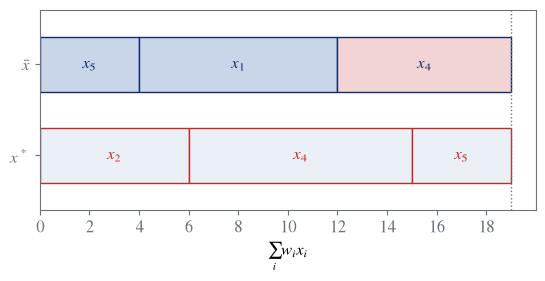

In [19]:
a1 = PUB["A1"]
p, w, W = a1["params"]["p"], a1["params"]["w"], a1["params"]["W"]
fig, ax = plt.subplots(figsize=(6.4, 2.6))
left = 0
for i in [k - 1 for k in a1["order"]]:
    share = 1 if w[i] <= W - left else (W - left) / w[i]
    if share <= 0:
        break
    ax.barh(1, w[i] * share, left=left, height=0.6, color=HSE["fill"] if share == 1 else HSE["fill2"],
            edgecolor=HSE["blue"], lw=1)
    ax.text(left + w[i] * share / 2, 1, rf"$x_{i + 1}$", ha="center", va="center", color=HSE["blue"])
    left += w[i] * share
left = 0
for i in [k - 1 for k in a1["set"]]:
    ax.barh(0, w[i], left=left, height=0.6, color=HSE["light"], edgecolor=HSE["accent"], lw=1)
    ax.text(left + w[i] / 2, 0, rf"$x_{i + 1}$", ha="center", va="center", color=HSE["accent"])
    left += w[i]
ax.axvline(W, color=HSE["gray"], lw=1, ls=":")
ax.set(xlim=(0, W + 1), ylim=(-0.6, 1.6), yticks=[0, 1], yticklabels=[r"$x^*$", r"$\bar x$"], xlabel=r"$\sum_i w_ix_i$",
       xticks=range(0, W + 1, 2))
save(fig, "fig_a1")
plt.show()

### fig_b1: the search tree of B1

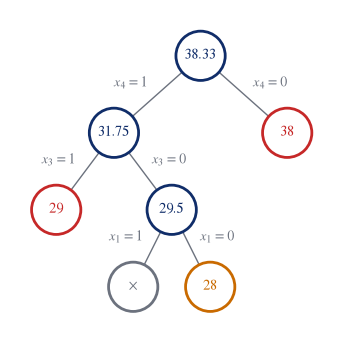

In [20]:
p, w, W = (PUB["B1"]["params"][k] for k in ("p", "w", "W"))
opt, log = depth_first(p, w, W)
keys = [tuple(nd["fixed"].items()) for nd in log]
children = {k: [c for c in keys if len(c) == len(k) + 1 and c[:len(k)] == k] for k in keys}
pos, slot = {}, [0]


def place(k, depth):
    if not children[k]:
        pos[k] = (slot[0], -depth)
        slot[0] += 1
    else:
        for c in children[k]:
            place(c, depth + 1)
        pos[k] = (sum(pos[c][0] for c in children[k]) / len(children[k]), -depth)


place((), 0)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for k in keys:
    for c in children[k]:
        (x0, y0), (x1, y1) = pos[k], pos[c]
        ax.plot([x0, x1], [y0, y1], color=HSE["gray"], lw=1, zorder=1)
        i, v = c[-1]
        side = -1 if x1 < x0 else 1
        ax.text((x0 + x1) / 2 + 0.12 * side, (y0 + y1) / 2 + 0.05, rf"$x_{i + 1}={v}$", fontsize=10, color=HSE["gray"],
                ha="right" if side < 0 else "left", va="bottom")
for k, nd in zip(keys, log):
    x, y = pos[k]
    b = nd["bound"]
    if b is None:
        color, label = HSE["gray"], r"$\times$"
    elif b <= nd["inc"]:
        color, label = HSE["orange"], rf"${float(b):.4g}$"
    elif fractional(lp_node(p, w, W, nd["fixed"])[1]) is None:
        color, label = HSE["accent"], rf"${float(b):.4g}$"
    else:
        color, label = HSE["blue"], rf"${float(b):.4g}$"
    ax.add_patch(plt.Circle((x, y), 0.32, facecolor="white", edgecolor=color, lw=2, zorder=2))
    ax.text(x, y, label, ha="center", va="center", fontsize=10, color=color, zorder=3)
ax.set(xlim=(-0.6, slot[0] - 0.4), ylim=(-max(len(k) for k in keys) - 0.6, 0.6), aspect="equal")
ax.axis("off")
save(fig, "fig_b1")
plt.show()

### fig_c1: the table and the way back

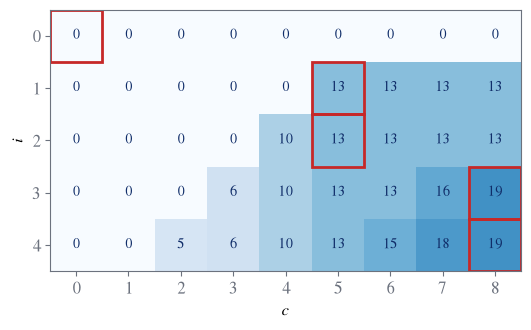

In [21]:
c1 = PUB["C1"]
Dt = np.array(c1["rows"])
p, w, W = (c1["params"][k] for k in ("p", "w", "W"))
path, c = [], W
for i in range(len(p), 0, -1):
    path.append((i, c))
    if Dt[i, c] != Dt[i - 1, c]:
        c -= w[i - 1]
path.append((0, c))
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.imshow(Dt, cmap="Blues", vmin=0, vmax=Dt.max() * 1.6)
for i in range(Dt.shape[0]):
    for c in range(Dt.shape[1]):
        ax.text(c, i, rf"${Dt[i, c]}$", ha="center", va="center", fontsize=10, color=HSE["blue"])
for i, c in path:
    ax.add_patch(plt.Rectangle((c - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=HSE["accent"], lw=2))
ax.set(xticks=range(W + 1), yticks=range(len(p) + 1), xlabel=r"$c$", ylabel=r"$i$")
save(fig, "fig_c1")
plt.show()

### fig_f2: nodes of branch and bound against the full tree

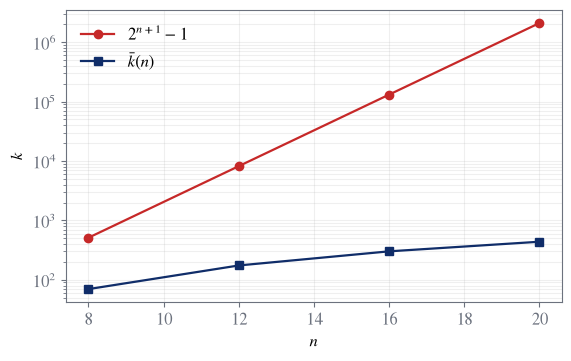

In [22]:
B = PUB["demo"]["bound"]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.semilogy(B["ns"], B["full"], "o-", color=HSE["accent"], lw=1.6, label=r"$2^{n+1}-1$")
ax.semilogy(B["ns"], B["nodes"], "s-", color=HSE["blue"], lw=1.6, label=r"$\bar k(n)$")
ax.set(xlabel=r"$n$", ylabel=r"$k$")
ax.legend(frameon=False)
ax.grid(alpha=0.2, which="both")
save(fig, "fig_f2")
plt.show()

## 8. Handout and cheat sheet

LaTeX for both languages is built from the content files; the token substitutions and the formatting follow render.js so the printed numbers equal those on the page.

In [23]:
TOKEN = re.compile(r"\{\{\s*([A-Za-z0-9.]+)\s*\}\}")


def merge_over(target, overlay):
    """The merge of access.js: objects key by key, arrays element by element, anything else replaced."""
    for key, b in overlay.items():
        a = target.get(key)
        if isinstance(a, dict) and isinstance(b, dict):
            merge_over(a, b)
        elif isinstance(a, list) and isinstance(b, list):
            for i, item in enumerate(b):
                if i < len(a) and isinstance(a[i], dict) and isinstance(item, dict):
                    merge_over(a[i], item)
                elif i < len(a):
                    a[i] = copy.deepcopy(item)
                else:
                    a.append(copy.deepcopy(item))
        else:
            target[key] = copy.deepcopy(b)
    return target


def value_at(data, path):
    node = at(data, path)
    if node is MISSING or node is None or isinstance(node, dict):
        raise KeyError(f"unresolved token {path}")
    return node


def is_num(v):
    return isinstance(v, (int, float)) and not isinstance(v, bool)


def decimal_str(v, digits=4):
    s = str(Decimal(v).quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))
    if "." in s:
        s = s.rstrip("0").rstrip(".")
    return "0" if s == "-0" else s


def tex_num(v, lang, math):
    s = decimal_str(v)
    if math:
        return s.replace(".", "{,}") if lang == "ru" else s
    s = s.replace(".", ",") if lang == "ru" else s
    return "−" + s[1:] if s.startswith("-") else s


def tex_value(v, lang, math):
    """render.value of render.js: a data value as TeX (math) or as text."""
    if is_num(v):
        return tex_num(v, lang, math)
    if isinstance(v, str):
        if math:
            return re.sub(r"(\d)\.(\d)", r"\1{,}\2", v).replace(r",\ ", r";\ ") if lang == "ru" else v
        if lang == "ru" and re.fullmatch(r"-?\d+\.\d+", v):
            v = v.replace(".", ",")
        return "−" + v[1:] if lang == "ru" and v.startswith("-") else v
    if isinstance(v, list) and v and all(is_num(x) for x in v):
        sep = (r";\ " if lang == "ru" else r",\ ") if math else ("; " if lang == "ru" else ", ")
        return "(" + sep.join(tex_num(x, lang, math) for x in v) + ")"
    if isinstance(v, list) and v and all(isinstance(r, list) and r and all(is_num(x) for x in r) for r in v):
        if not math:
            return " ".join(tex_value(r, lang, False) for r in v)
        rows = r" \\ ".join(" & ".join(tex_num(x, lang, True) for x in r) for r in v)
        return r"\begin{pmatrix} " + rows + r" \end{pmatrix}"
    return None


def tex_token(path, data, lang, math):
    v = value_at(data, path)
    tex = tex_value(v, lang, True)
    assert tex is not None, path
    if math:
        return tex
    text = tex_value(v, lang, False)
    return text if re.fullmatch(r"[0-9.,]+", text) else "$" + tex + "$"


def tex_segments(s):
    r"""The segmenter of render.js: $$display$$, $inline$, \$ a literal dollar, text; a lone $ is text."""
    out, buf, i = [], "", 0
    while i < len(s):
        ch = s[i]
        if ch == "\\" and s[i + 1 : i + 2] == "$":
            buf += "\x03"
            i += 2
            continue
        if ch == "$":
            display = s[i + 1 : i + 2] == "$"
            n = 2 if display else 1
            close = s.find("$$" if display else "$", i + n)
            if close < 0:
                buf += s[i:]
                break
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", s[i + n : close]))
            i = close + n
            continue
        buf += ch
        i += 1
    if buf:
        out.append(("text", buf))
    return out


ESC = [("{", r"\{"), ("}", r"\}"), ("%", r"\%"), ("&", r"\&"), ("#", r"\#"), ("_", r"\_"),
       ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}")]


def esc(text):
    text = text.replace("\\", "\x00")
    for a, b in ESC:
        text = text.replace(a, b)
    return text.replace("\x00", r"\textbackslash{}")


def rich(s, data, lang):
    """One content string as LaTeX: tokens become numbers and markup goes to \\textbf, \\emph, \\texttt."""
    segs = []
    for kind, seg in tex_segments(s):
        if kind == "display" and len(segs) > 1 and segs[-2][0] == "display" and segs[-1][0] == "text" \
                and not segs[-1][1].strip():
            segs.pop()
        if kind == "display" and segs and segs[-1][0] == "display":
            segs[-1][1].append(seg)
        else:
            segs.append((kind, [seg] if kind == "display" else seg))
    parts = []
    for kind, seg in segs:
        if kind == "display":
            lines = " \\\\[6pt]\n".join(b.strip() for b in seg)
            seg = lines if len(seg) == 1 else "\\begin{gathered}\n" + lines + "\n\\end{gathered}"
        if kind in ("math", "display"):
            body = TOKEN.sub(lambda m: tex_token(m.group(1), data, lang, True), seg)
            body = body.replace(" ", " ").replace(" ", r"\,")
            assert "%" not in body and "#" not in body and "{{" not in body, seg
            display = "\n\\handoutdisplay{\n" + body.strip() + "\n}\n"
            parts.append("$" + body + "$" if kind == "math" else display)
            continue
        toks, codes = [], []
        t = TOKEN.sub(lambda m: toks.append(m.group(1)) or f"\x01{len(toks) - 1}\x01", seg)
        t = re.sub(r"`([^`]+)`", lambda m: codes.append(esc(m.group(1))) or f"\x02{len(codes) - 1}\x02", t)
        t = esc(t).replace("\x03", r"\$").replace(" ", "~").replace(" ", r"\,")
        t = re.sub(r"\*\*([^*]+)\*\*", r"\\textbf{\1}", t)
        t = re.sub(r"\*([^*\s][^*]*)\*", r"\\emph{\1}", t)
        t = re.sub("\x02(\\d+)\x02", lambda m: r"\texttt{" + codes[int(m.group(1))] + "}", t)
        t = re.sub("\x01(\\d+)\x01", lambda m: tex_token(toks[int(m.group(1))], data, lang, False), t)
        parts.append(t)
    out = "".join(parts)
    assert not re.search("[\x00-\x03 ]", out), s
    return out


def tr(pair, data, lang, inline=False):
    """A pair as LaTeX; a missing Russian half falls back to the English half with English hyphenation."""
    if pair.get(lang):
        return rich(pair[lang], data, lang)
    tex = rich(pair["en"], data, "en")
    if lang == "en":
        return tex
    return "\\textenglish{" + tex + "}" if inline else "\\begin{english}\n" + tex + "\n\\end{english}"


FIG_WIDTH = {"fig_a1": 0.72, "fig_b1": 0.66, "fig_c1": 0.72, "fig_f2": 0.72}
LABELS = {
    "en": {"course": "Optimization Methods", "seminar": "Seminar 10", "page": "Theory handout",
           "topic": "Knapsack and Linear Programming in Practice",
           "institution": "HSE University, Faculty of Computer Science", "year": "Academic year 2026-2027",
           "lecturer": "Course lecturer: Andrey Ignatov", "author": "Evgeny Baulin",
           "byline": "Author: Evgeny Baulin", "license": "MIT License", "kicker": "Seminar 10 cheat sheet",
           "definition": "Definition", "theorem": "Theorem", "lemma": "Lemma", "corollary": "Corollary",
           "proposition": "Proposition", "proof": "Proof", "example": "Example", "intuition": "Why",
           "trap": "Trap", "selfcheck": "Check yourself", "answer": "Answer", "convention": "Notation",
           "figure": "Figure", "statement": "Statement", "solution": "Solution",
           "board": "On the board", "students": "On your own"},
    "ru": {"course": "Методы оптимизации", "seminar": "Семинар 10", "page": "Конспект теории",
           "topic": "Рюкзак и линейное программирование на практике",
           "institution": "НИУ ВШЭ, факультет компьютерных наук", "year": "2026-2027 учебный год",
           "lecturer": "Лектор курса: Андрей Игнатов", "author": "Евгений Баулин",
           "byline": "Автор: Евгений Баулин", "license": "Лицензия MIT", "kicker": "Шпаргалка к семинару 10",
           "definition": "Определение", "theorem": "Теорема", "lemma": "Лемма", "corollary": "Следствие",
           "proposition": "Утверждение", "proof": "Доказательство", "example": "Пример",
           "intuition": "Почему", "trap": "Ловушка", "selfcheck": "Проверьте себя", "answer": "Ответ",
           "convention": "Обозначения", "figure": "Рисунок", "statement": "Условие", "solution": "Решение",
           "board": "У доски", "students": "Самостоятельно"},
}


def period(s):
    return s if s.endswith((".", "?", "!")) else s + "."


def block_tex(b, content, data, lang):
    t, L = b["type"], LABELS[lang]
    text = lambda pair: tr(pair, data, lang)
    title = lambda pair: tr(pair, data, lang, inline=True)
    if t == "p":
        return text(b["text"])
    if t in ("example", "intuition"):
        env = "examplebox" if t == "example" else "whybox"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "list":
        items = "\n".join("  \\item " + text(i) for i in b["items"])
        return "\\begin{itemize}\n" + items + "\n\\end{itemize}"
    if t == "figure":
        name = re.fullmatch(r"(?:figures/)?(fig_[a-z0-9_]+)(?:\.svg)?", b["src"]).group(1)
        cap = text(b["caption"]) if b.get("caption") else ""
        return f"\\handoutfigure{{{FIG_WIDTH[name]:g}}}{{{name}}}{{{cap}}}"
    if t in ("definition", "theorem"):
        kind = "definition" if t == "definition" else b.get("kind", "theorem")
        label = L[kind] + (": " + title(b["title"]) if b.get("title") else "")
        env = "definitionbox" if t == "definition" else "theorembox"
        return f"\\begin{{{env}}}{{{period(label)}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t in ("proof", "trap"):
        env = t + "box"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "note":
        return f"\\begin{{notebox}}{{{title(b['title'])}}}\n{text(b['text'])}\n\\end{{notebox}}"
    if t == "selfcheck":
        return (f"\\begin{{selfcheckbox}}\n{text(b['question'])}\n"
                f"\\selfcheckanswer {text(b['answer'])}\n\\end{{selfcheckbox}}")
    if t == "problem":
        return problem_tex(b["id"], content, data, lang)
    raise ValueError(f"unknown block type {t}")


def problem_tex(pid, content, data, lang):
    P, L = content["problems"][pid], LABELS[lang]
    steps = ["  \\item " + tr(st["text"], data, lang) for st in P["steps"]]
    return "\n".join([
        f"\\problemhead{{{pid}}}{{{tr(P['title'], data, lang, inline=True)}}}{{{L[P['who']]}}}",
        f"\\textbf{{{L['statement']}.}} {tr(P['statement'], data, lang)}",
        "",
        f"\\textbf{{{L['solution']}.}}",
        "\\begingroup\\sloppy",
        "\\begin{enumerate}[label=\\textbf{\\arabic*.}, leftmargin=*]",
        *steps,
        "\\end{enumerate}",
        "\\endgroup",
        "\\begin{answerbox}",
        tr(P["answerText"], data, lang),
        "\\end{answerbox}",
    ])


def fill(template, values):
    for name, tex in values.items():
        placeholder = f"<<{name}>>"
        assert template.count(placeholder) == 1, name
        template = template.replace(placeholder, tex)
    assert "<<" not in template
    return template


def tidy(doc):
    """No trailing spaces: a text segment before a display keeps the space it ended with."""
    return "\n".join(line.rstrip() for line in doc.split("\n"))

In [24]:
LANGUAGE_SETUP = {
    "en": r"""\usepackage{polyglossia}
\setdefaultlanguage{english}""",
    "ru": r"""\usepackage{polyglossia}
\setdefaultlanguage{russian}
\setotherlanguage{english}
\newfontfamily\cyrillicfont{cmunrm.otf}[Ligatures=TeX, BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\newfontfamily\cyrillicfontsf{cmunss.otf}[Ligatures=TeX, BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\newfontfamily\cyrillicfonttt{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]""",
}

THEORY_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 10: theory handout (<<language>>).
% Generated by checks/10. Knapsack and Linear Programming in Practice.ipynb from web/10/js/content-*.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\documentclass[11pt,a4paper]{article}

\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=2.3cm,right=2.3cm,top=2.4cm,bottom=2.4cm,headheight=14pt]{geometry}
\usepackage{amsmath,amssymb}
\usepackage{graphicx}
\usepackage{array,booktabs,longtable}
\usepackage{enumitem}
\usepackage{xcolor}
\usepackage[most]{tcolorbox}
\usepackage{titlesec}
\usepackage{fancyhdr}
\usepackage{needspace}
\usepackage[expansion=false]{microtype}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue,citecolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}
\definecolor{hsewarm}{RGB}{253,244,232}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

\titleformat{\section}{\color{hseblue}\Large\bfseries}{\thesection}{0.6em}{}
\titleformat{\subsection}{\color{hseblue}\large\bfseries}{\thesubsection}{0.6em}{}
\titlespacing*{\section}{0pt}{16pt plus 4pt minus 2pt}{8pt plus 2pt}
\titlespacing*{\subsection}{0pt}{12pt plus 3pt minus 2pt}{6pt plus 2pt}
\pretocmd{\section}{\Needspace{7\baselineskip}}{}{\errmessage{cannot patch section}}
\pretocmd{\subsection}{\Needspace{5\baselineskip}}{}{\errmessage{cannot patch subsection}}

\tcbset{handoutbox/.style={enhanced, breakable, sharp corners, boxrule=0pt, left=7pt, right=7pt, top=5pt, bottom=5pt, before skip=8pt plus 2pt, after skip=8pt plus 2pt}}
\newtcolorbox{examplebox}{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries <<labelExample>>}\ }}
\newtcolorbox{whybox}{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelWhy>>}\ }}
\newtcolorbox{answerbox}{handoutbox, colback=hsewarm, colframe=hsewarm, before upper={\textcolor{hseaccent}{\bfseries <<labelAnswer>>}\ }}
\newtcolorbox{conventionbox}{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries <<labelConvention>>}\par\smallskip}}

\newcommand{\handoutfigure}[3]{\par\medskip\noindent\begin{minipage}{\linewidth}\centering
  \includegraphics[width=#1\linewidth]{figures/#2.pdf}\par\smallskip
  \begin{minipage}{0.94\linewidth}\small\textcolor{hseblue}{\bfseries <<labelFigure>>}\ #3\end{minipage}\end{minipage}\par\medskip}
\newcommand{\problemhead}[3]{\par\bigskip\noindent{\color{hseblue}\large\bfseries #1.\ #2}\par\nopagebreak
  \noindent{\small\itshape\color{hsegray}#3}\par\nopagebreak\smallskip}
\newtcolorbox{definitionbox}[1]{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{theorembox}[1]{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{proofbox}{handoutbox, colback=white, colframe=hsegray, leftrule=1.2pt, top=3pt, bottom=3pt, before upper={\textcolor{hsegray}{\bfseries\itshape <<labelProof>>}\ }}
\newtcolorbox{notebox}[1]{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries #1}\par\smallskip}}
\newtcolorbox{trapbox}{handoutbox, colback=hsewarm, colframe=hseaccent, leftrule=2.5pt, before upper={\textcolor{hseaccent}{\bfseries <<labelTrap>>}\ }}
\newtcolorbox{selfcheckbox}{handoutbox, colback=white, colframe=hseaccent, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelSelfcheck>>}\ }}
\newcommand{\handoutdisplay}[1]{\sbox0{$\displaystyle #1$}\ifdim\wd0>\linewidth
  \par{\centering\binoppenalty=10000\relpenalty=0\relax$\displaystyle #1$\par}\else\[#1\]\fi}
\newcommand{\selfcheckanswer}{\par\smallskip\textcolor{hsegray}{\bfseries <<labelSelfcheckAnswer>>}\ }

\setlist[itemize]{itemsep=3pt,topsep=4pt}
\setlist[enumerate]{itemsep=3pt,topsep=4pt}
\setlength{\parindent}{0pt}
\setlength{\parskip}{5pt plus 1pt}
\setlength{\emergencystretch}{2em}
\setcounter{tocdepth}{2}

\pagestyle{fancy}
\fancyhf{}
\fancyhead[L]{\small\color{hsegray}<<headerCourse>>}
\fancyhead[R]{\small\color{hsegray}<<headerSeminar>>}
\fancyfoot[L]{\small\color{hsegray}<<footerAuthor>>}
\fancyfoot[C]{\small\thepage}
\fancyfoot[R]{\small\color{hsegray}<<footerLicense>>}
\renewcommand{\headrulewidth}{0pt}
\renewcommand{\footrulewidth}{0pt}
\fancypagestyle{plain}{\pagestyle{fancy}}

\begin{document}

\begin{center}
  {\large\color{hsegray}<<titleCourse>>\par}
  \vspace{4pt}
  {\large\bfseries\color{hseaccent}<<titleSeminar>>\par}
  \vspace{8pt}
  {\LARGE\bfseries\color{hseblue}<<titleTopic>>\par}
  \vspace{8pt}
  {\Large <<titlePage>>\par}
  \vspace{12pt}
  <<titleInstitution>>\par
  <<titleYear>>\par
  \vspace{8pt}
  <<titleLecturer>>\par
  <<titleAuthor>>\par
  Telegram: \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}\par
\end{center}

\noindent{\color{hseblue}\rule{\linewidth}{0.6pt}}

\tableofcontents

\clearpage
"""

CHEAT_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 10: one-page cheat sheet (<<language>>).
% Generated by checks/10. Knapsack and Linear Programming in Practice.ipynb from web/10/js/content-cheatsheet.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\RequirePackage{fix-cm}
\documentclass[10pt,a4paper]{article}

\usepackage{amsmath,amssymb}
\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=8mm,right=8mm,top=7mm,bottom=11mm,footskip=5.5mm]{geometry}
\usepackage{xcolor}
\usepackage{multicol}
\usepackage{enumitem}
\usepackage{ragged2e}
\usepackage{fancyhdr}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

\pagestyle{fancy}
\fancyhf{}
\renewcommand{\headrulewidth}{0pt}
\fancyfoot[L]{\scriptsize\color{hsegray}\textcopyright\ 2026 <<footerAuthor>>, \href{https://t.me/tarakan_tuc}{t.me/tarakan\_tuc}}
\fancyfoot[R]{\scriptsize\color{hsegray}<<footerLicense>>}

\setlength{\parindent}{0pt}
\setlength{\parskip}{0pt}
\setlength{\columnsep}{4.5mm}
\setlength{\columnseprule}{0.3pt}
\renewcommand{\columnseprulecolor}{\color{hselight}}
\setlength{\emergencystretch}{2em}
\setlength{\RaggedRightRightskip}{0pt plus 4em}
\binoppenalty=2000
\relpenalty=500
\setlength{\abovedisplayskip}{2pt}
\setlength{\belowdisplayskip}{2pt}
\setlist[itemize]{leftmargin=7pt, labelsep=3pt, itemsep=1.2pt, topsep=1pt, parsep=0pt, partopsep=0pt,
  label={\color{hseaccent}\scriptsize\textbullet}}

\makeatletter
\newcommand{\cssec}[1]{\par\addvspace{3.5pt}\noindent
  \colorbox{hselight}{\parbox{\dimexpr\linewidth-2\fboxsep}{\RaggedRight\hyphenpenalty=10000\color{hseblue}\bfseries\strut #1}}%
  \par\nobreak\vspace{1pt}\@afterheading}
\makeatother
\clubpenalty=10000
\widowpenalty=10000

\begin{document}
\thispagestyle{fancy}

\noindent
\begin{minipage}[b]{0.6\textwidth}
  \RaggedRight\hyphenpenalty=10000
  {\color{hseaccent}\bfseries\small <<kicker>>}\\[1pt]
  {\color{hseblue}\bfseries\Large <<title>>}
\end{minipage}\hfill
\begin{minipage}[b]{0.39\textwidth}
  \raggedleft\footnotesize
  {\bfseries <<course>>}\\
  <<institution>>, 2026--2027\\
  <<lecturer>>\\
  <<byline>>, Telegram \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}
\end{minipage}

\vspace{2pt}
{\color{hseblue}\rule{\textwidth}{0.8pt}}
\vspace{-4pt}

\fontsize{9}{<<leading>>}\selectfont
\begin{multicols}{3}
\RaggedRight
"""


def theory_tex(lang, content, data):
    h, L = content["handout"], LABELS[lang]
    topic = h["title"][lang] if h["title"].get(lang) else L["topic"]
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Theory_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang],
        "pdftitle": esc(f"{L['course']}. {L['seminar']}. {L['page']}"),
        "pdfauthor": esc(L["author"]),
        "labelExample": period(L["example"]),
        "labelWhy": period(L["intuition"]),
        "labelAnswer": period(L["answer"]),
        "labelConvention": period(L["convention"]),
        "labelFigure": period(L["figure"]),
        "labelProof": period(L["proof"]),
        "labelTrap": period(L["trap"]),
        "labelSelfcheck": period(L["selfcheck"]),
        "labelSelfcheckAnswer": period(L["answer"]),
        "headerCourse": esc(L["course"]),
        "headerSeminar": esc(L["seminar"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "titleCourse": esc(L["course"]),
        "titleSeminar": esc(L["seminar"]),
        "titleTopic": rich(topic, data, lang),
        "titlePage": esc(L["page"]),
        "titleInstitution": esc(L["institution"]),
        "titleYear": esc(L["year"]),
        "titleLecturer": esc(L["lecturer"]),
        "titleAuthor": esc(L["author"]),
    }
    out = [fill(THEORY_PREAMBLE, values), "", tr(h["intro"], data, lang), "",
           "\\begin{conventionbox}", tr(h["convention"], data, lang), "\\end{conventionbox}", ""]
    for sec in h["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += ["% " + "=" * 69, f"\\section{{{heading}}}\\label{{sec:{sec['id']}}}", ""]
        for b in sec.get("blocks", []):
            out += [block_tex(b, content, data, lang), ""]
        for sub in sec.get("subsections", []):
            heading = tr(sub["title"], data, lang, inline=True)
            out += [f"\\subsection{{{heading}}}\\label{{sub:{sub['id']}}}", ""]
            for b in sub.get("blocks", []):
                out += [block_tex(b, content, data, lang), ""]
    out.append("\\end{document}")
    return tidy("\n".join(out)) + "\n"


def split_title(title):
    """Two lines, broken at the space nearest to the middle that does not follow a short word."""
    spaces = [i for i, ch in enumerate(title) if ch == " " and len(title[:i].split(" ")[-1]) > 3]
    cut = min(spaces, key=lambda i: abs(i - len(title) / 2))
    return title[:cut] + "\\\\ " + title[cut + 1:]


def cheat_tex(lang, content, data):
    cs, L = content["cheatsheet"], LABELS[lang]
    hyphenation = "\n\\PolyglossiaSetup{russian}{hyphenmins={2,3}}" if lang == "ru" else ""
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Cheatsheet_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang] + hyphenation,
        "pdftitle": esc(f"{L['kicker']}: {cs['title'][lang]}"),
        "pdfauthor": esc(L["author"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "kicker": esc(L["kicker"]),
        "title": split_title(tr(cs["title"], data, lang, inline=True)),
        "course": esc(L["course"]),
        "institution": esc(L["institution"]),
        "lecturer": esc(L["lecturer"]),
        "byline": esc(L["byline"]),
        "leading": {"en": "11.4", "ru": "10.6"}[lang],
    }
    out = [fill(CHEAT_PREAMBLE, values), ""]
    for sec in cs["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += [f"% ---- {sec['id']}", f"\\cssec{{{heading}}}", "\\begin{itemize}"]
        out += ["  \\item " + tr(item, data, lang, inline=True) for item in sec["items"]]
        out += ["\\end{itemize}", ""]
    out += ["\\end{multicols}", "\\end{document}"]
    return tidy("\n".join(out)) + "\n"


def latex_sources(content, data):
    return {**{f"Theory_{lang}": theory_tex(lang, content, data) for lang in ("en", "ru")},
            **{f"Cheatsheet_{lang}": cheat_tex(lang, content, data) for lang in ("en", "ru")}}


assert sorted(FIG_WIDTH) == sorted(FIGURES), FIGURES
LATEX = latex_sources(merge_over(copy.deepcopy(PUBLIC["content"]), STUDENTS["content"]),
                      merge_over(copy.deepcopy(PUB), STU))
for name, text in LATEX.items():
    written = write_if_changed(THEORY / f"{name}.tex", text)
    print(f"{name}.tex: {text.count(chr(10))} lines, {'written' if written else 'unchanged'}")

Theory_en.tex: 473 lines, unchanged
Theory_ru.tex: 477 lines, unchanged
Cheatsheet_en.tex: 137 lines, unchanged
Cheatsheet_ru.tex: 142 lines, unchanged


## 9. Content consistency

Every visible string is an `{en, ru}` pair; every token resolves; no stray number or external URL leaks into the page or the handout.

In [25]:
REQUIRE_RU = True
CYR = re.compile("[\\u0400-\\u04FF]")
TELEGRAM = "https://t.me/tarakan_tuc"
NOT_TEXT = {"id", "who", "ref", "type", "kind", "src", "v", "keys", "pages"}
PROBLEM_IDS = [f"{b}{k}" for b in "ABCD" for k in (1, 2, 3)]
TEXT_SUFFIXES = {".html", ".css", ".js", ".json", ".svg", ".tex", ".txt", ".md", ".py", ".sh", ".ipynb",
                 ".service", ".timer"}


def visible(node, where, problems, untranslated):
    if isinstance(node, dict):
        if "en" in node or "ru" in node:
            if "en" not in node or not set(node) <= {"en", "ru"}:
                problems.append(f"{where}: keys {sorted(node)}")
            if "ru" not in node:
                untranslated.append(where)
            for lang in ("en", "ru"):
                if lang not in node:
                    continue
                if not isinstance(node[lang], str) or not node[lang].strip():
                    problems.append(f"{where}: empty or non-string '{lang}'")
                else:
                    yield where, lang, node[lang]
            return
        for k, v in node.items():
            yield from visible(v, f"{where}.{k}", problems, untranslated)
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from visible(v, f"{where}[{i}]", problems, untranslated)
    elif isinstance(node, str) and where.rsplit(".", 1)[-1].split("[")[0] not in NOT_TEXT:
        problems.append(f"{where}: a bare string")


def cyrillic_outside_ru(node, where):
    if isinstance(node, dict):
        for k, v in node.items():
            if CYR.search(k):
                yield f"{where}: the key {k}"
            if (k == "ru" and "en" in node) or (where.startswith("data") and k.endswith("Ru")):
                continue
            yield from cyrillic_outside_ru(v, f"{where}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from cyrillic_outside_ru(v, f"{where}[{i}]")
    elif isinstance(node, str) and CYR.search(node):
        yield where


def resolves(path, roots):
    return any(at(root, path) is not MISSING and not isinstance(at(root, path), dict) for root in roots)


def segments(text):
    out, buf, i = [], "", 0
    while i < len(text):
        if text[i] == "\\" and text[i + 1:i + 2] == "$":
            buf += "$"
            i += 2
            continue
        if text[i] == "$":
            display = text[i + 1:i + 2] == "$"
            width = 2 if display else 1
            close = text.find("$$" if display else "$", i + width)
            if close < 0:
                return None
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", text[i + width:close]))
            i = close + width
            continue
        buf += text[i]
        i += 1
    if buf:
        out.append(("text", buf))
    return out


def stray_digits(kind, piece):
    piece = TOKEN.sub("", piece)
    if kind == "text":
        piece = re.sub(r"\b[A-Z]\d\b", "", piece)
        piece = re.sub(r"\b[Tt]asks? \d+(?:(?:, | and | to |-)\d+)*", "", piece)
        piece = re.sub(r"\b[Зз]адач\w*\s\d+(?:(?:,\s|\sи\s|\sдо\s|-)\d+)*", "", piece)
        piece = re.sub(r"\b[Ss]eminars?\s\d+(?:(?:, | and | to |-)\d+)*", "", piece)
        piece = re.sub(r"\b[Сс]еминар\w*\s\d+(?:(?:,\s|\sи\s|\sдо\s|-)\d+)*", "", piece)
        piece = re.sub(r"\b202[67]\b", "", piece)
        return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if m not in {"0", "1", "2", SEMINAR, SEMINAR[1]}]
    return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if len(m) > 1]


def pdf_pages(path):
    raw = Path(path).read_bytes()
    blobs = [raw]
    for m in re.finditer(rb"stream\r?\n(.*?)\r?\nendstream", raw, re.S):
        try:
            blobs.append(zlib.decompressobj().decompress(m.group(1)))
        except zlib.error:
            pass
    counts = []
    for b in blobs:
        for d in re.findall(rb"<<(?:[^<>]|<<[^<>]*>>)*?/Type\s*/Pages\b(?:[^<>]|<<[^<>]*>>)*?>>", b):
            counts += [int(c) for c in re.findall(rb"/Count\s+(\d+)", d)]
    return max(counts) if counts else None

In [26]:
DOCS = {}
for name in ("public", "students", "teacher"):
    path = CONTENT / f"{name}.json"
    try:
        DOCS[name] = strict_json(path)
        error = None
    except (OSError, ValueError) as err:
        DOCS[name], error = {}, str(err)
    check(f"consistency: {name}.json is strict JSON", error or "ok", "ok")
    check(f"consistency: {name}.json has id seminar-10", DOCS[name].get("id"), "seminar-10")
    check(f"consistency: {name}.json has Cyrillic only in ru strings and data leaves named ...Ru",
          [w for k, v in DOCS[name].items() for w in cyrillic_outside_ru(v, k)], [])
check("consistency: public.json holds only the numbers, the public text is in web/10/js",
      sorted(DOCS["public"]), ["data", "id"])

public_content, top_keys = {}, []
for path in CONTENT_FILES:
    try:
        obj, outside = marked_json(path)
        error = None
    except (OSError, ValueError) as err:
        obj, outside, error = {}, "", str(err)
    check(f"consistency: {path.name} has strict JSON between the markers", error or "ok", "ok")
    check(f"consistency: {path.name} has no Cyrillic outside the JSON", CYR.search(outside) is None, True)
    top_keys += list(obj)
    public_content.update(obj)
check("consistency: the content files hold seminar, main, problems, handout and cheatsheet, one each",
      top_keys, ["seminar", "main", "problems", "handout", "cheatsheet"])
check("consistency: the public content has Cyrillic only in ru strings",
      list(cyrillic_outside_ru(public_content, "content")), [])
DOCS["public"]["content"] = public_content

LABEL = {"public": "the public content", "students": "students.json", "teacher": "teacher.json"}
data = {name: DOCS[name].get("data", {}) for name in DOCS}
roots = {"public": [data["public"]], "students": [data["public"], data["students"]],
         "teacher": [data["public"], data["students"], data["teacher"]]}
filled, untranslated_total = [], 0
for name, doc in DOCS.items():
    problems, untranslated = [], []
    texts = list(visible(doc.get("content", {}), f"{name}.content", problems, untranslated))
    pairs = sum(lang == "en" for _, lang, _ in texts)
    if texts:
        filled.append(f"{name}: {pairs} strings, untranslated: {len(untranslated)}")
    untranslated_total += len(untranslated)
    label = LABEL[name]
    check(f"consistency: {label}: every visible string is an {{en, ru}} pair of non-empty strings",
          problems, [])
    check(f"consistency: {label}: every pair has its ru", untranslated if REQUIRE_RU else [], [])
    check(f"consistency: {label}: no Cyrillic in en", [w for w, lang, s in texts
                                                       if lang == "en" and CYR.search(s)], [])
    tokens = sorted({f"{w}.{lang}: {t}" for w, lang, s in texts for t in TOKEN.findall(s)
                     if t.startswith("TODO.") or not resolves(t, roots[name])})
    check(f"consistency: {label}: every token resolves in the data it may see", tokens, [])
    digits = []
    for w, lang, s in texts:
        parts = segments(s)
        if parts is None:
            digits.append(f"{w}.{lang}: a $ is not closed")
            continue
        for kind, piece in parts:
            if stray_digits(kind, piece):
                digits.append(f"{w}.{lang}: {kind} {stray_digits(kind, piece)}")
    check(f"consistency: {label}: no literal numbers outside tokens", digits, [])
    markup = [f"{w}.{lang}" for w, lang, s in texts if re.search(r"<[a-zA-Z/!]|https?://|www\.", s)]
    check(f"consistency: {label}: no HTML and no links in the text", markup, [])

pub_c, stu_c, tea_c = (DOCS[n].get("content", {}) for n in ("public", "students", "teacher"))
pub_problems = pub_c.get("problems", {})
known = list(pub_problems) or PROBLEM_IDS
pub_specs, stu_specs = data["public"].get("answers", {}), data["students"].get("answers", {})
specs = {**pub_specs, **stu_specs}
check("consistency: the public problems are A1 to D3",
      sorted(pub_problems) if pub_problems else PROBLEM_IDS, PROBLEM_IDS)
parts_off = []
for pid, P in pub_problems.items():
    parts = [(part.get("id"), part.get("ref")) for part in P.get("answers", [])]
    if parts != [(k, f"answers.{pid}.{k}") for k in specs.get(pid, {})]:
        parts_off.append(pid)
    for _, ref in parts:
        spec = at(data["public" if pid in pub_specs else "students"], str(ref))
        if not isinstance(spec, dict) or "type" not in spec:
            parts_off.append(f"{pid}: {ref}")
if pub_problems:
    parts_off += [f"{pid}: specs without a problem" for pid in specs if pid not in pub_problems]
check("consistency: one answer part per answers.* spec, in order, each resolving to a spec", parts_off, [])
board = [pid for pid, P in pub_problems.items() if P.get("who") == "board"]
BOARD = [f"{b}1" for b in "ABCD"]
OWN = [p for p in PROBLEM_IDS if p not in BOARD]
check("consistency: the board problems A1 to D1 are public in full with their answer specs; "
      "the students problems keep specs and solutions locked",
      [board, sorted(pub_specs), sorted(p for p in pub_problems if "steps" in pub_problems[p]),
       sorted(stu_specs), sorted(stu_c.get("problems", {}))],
      [BOARD, BOARD, BOARD, OWN, OWN])
check("consistency: students and teacher problems exist publicly",
      [p for p in list(stu_c.get("problems", {})) + list(tea_c.get("teacher", {}).get("problems", {}))
       if p not in known], [])
blocks = data["public"]["timeline"]["blocks"]
check("consistency: public main.blocks are timeline.blocks, in order",
      list(pub_c.get("main", {}).get("blocks", {})) or blocks, blocks)
other_blocks = [*stu_c.get("main", {}).get("blocks", {}), *tea_c.get("teacher", {}).get("blocks", {})]
check("consistency: students and teacher blocks are among timeline.blocks",
      [b for b in other_blocks if b not in blocks], [])
pub_figs = sorted({d["src"] for d in nodes(pub_c) if isinstance(d.get("src"), str)})
fig_refs = {d["src"] for c in (pub_c, stu_c) for d in nodes(c) if isinstance(d.get("src"), str)}
check("consistency: every figure the public and students content name exists as SVG and PDF",
      sorted(s for s in fig_refs if s not in FIGURES or not (FIG_DIR / f"{s}.svg").is_file()
             or not (FIG_DIR / f"{s}.pdf").is_file()), [])
web_figs = WEB / "figures"
check("consistency: web/10/figures holds the figures of the public content, as the same SVG",
      [p.name for p in sorted(web_figs.iterdir()) if p.name != ".DS_Store"] if web_figs.is_dir() else [],
      [f"{s}.svg" for s in pub_figs])
check("consistency: web/10/figures/*.svg equal the handout's",
      [s for s in pub_figs if not (web_figs / f"{s}.svg").is_file()
       or (web_figs / f"{s}.svg").read_bytes() != (FIG_DIR / f"{s}.svg").read_bytes()], [])
check("consistency: the teacher content names no figure",
      sorted(d["src"] for d in nodes(tea_c) if isinstance(d.get("src"), str)), [])
embedded = {d.get("id") for d in nodes(stu_c.get("handout", {})) if d.get("type") == "problem"}
check("consistency: every problem the handout embeds exists", sorted(embedded - set(known)), [])

web_hits = []
for path in sorted(WEB.rglob("*")):
    if not path.is_file() or path.suffix not in TEXT_SUFFIXES:
        continue
    rel = path.relative_to(WEB).as_posix()
    text = path.read_text(encoding="utf-8", errors="replace")
    if path.suffix != ".svg":
        for needle in ("fetch(", "XMLHttpRequest", "import ", "export "):
            allowed = 1 if (rel == "js/access.js" and needle == "fetch(") else 0
            if text.count(needle) > allowed:
                web_hits.append(f"{rel}: {needle!r} x{text.count(needle)}")
        urls = re.findall(r"https?://[^\s\"'<>)\\]+", text)
        web_hits += [f"{rel}: {url}" for url in urls if url != TELEGRAM]
    if path in CONTENT_FILES:
        text = re.sub(r"/\*JSON-BEGIN\*/.*/\*JSON-END\*/", "", text, flags=re.S)
    if CYR.search(text) and rel != f"data/seminar{SEMINAR}_data.js":
        web_hits.append(f"{rel}: Cyrillic")
check("consistency: web/10 has no fetch (but one in js/access.js), XMLHttpRequest, import, export, "
      "foreign URL, or Cyrillic outside the data file and the JSON of the content files", web_hits, [])
cyr_files = [p.relative_to(THEORY).as_posix() for p in sorted(THEORY.rglob("*"))
             if p.is_file() and p.suffix in TEXT_SUFFIXES and not p.name.endswith("_ru.tex")
             and not (p.parent == CONTENT and p.suffix == ".json")
             and CYR.search(p.read_text(encoding="utf-8", errors="ignore"))]
check("consistency: Cyrillic in the theory folder only in content/*.json and *_ru.tex", cyr_files, [])
check("consistency: the four figures are written", sorted(FIGURES), ["fig_a1", "fig_b1", "fig_c1", "fig_f2"])

try:
    fresh = latex_sources(merge_over(copy.deepcopy(public_content), DOCS["students"].get("content", {})),
                          merge_over(copy.deepcopy(data["public"]), data["students"]))
    stale = [name for name, text in fresh.items() if not (THEORY / f"{name}.tex").is_file()
             or (THEORY / f"{name}.tex").read_bytes() != text.encode("utf-8")]
except (KeyError, TypeError, ValueError, AssertionError) as err:
    stale = [f"no generation: {err!r}"]
check("consistency: the four LaTeX files on disk equal a fresh generation", stale, [])
FIGREF = re.compile(r"\\handoutfigure\{[^{}]*\}\{([^{}]+)\}")
pdf_problems, pages = [], {}
for name in LATEX:
    tex, pdf, log = (THEORY / f"{name}{suffix}" for suffix in (".tex", ".pdf", ".log"))
    if not pdf.is_file():
        pdf_problems.append(f"{name}.pdf missing")
        continue
    text = tex.read_text(encoding="utf-8") if tex.is_file() else ""
    sources = [tex] + [FIG_DIR / f"{n}.pdf" for n in FIGREF.findall(text)]
    for source in sources:
        if not source.is_file():
            pdf_problems.append(f"{name}.pdf: {source.relative_to(THEORY).as_posix()} missing")
        elif pdf.stat().st_mtime < source.stat().st_mtime - 2:
            pdf_problems.append(f"{name}.pdf older than {source.relative_to(THEORY).as_posix()}")
    pages[name] = pdf_pages(pdf)
    if name.startswith("Cheatsheet") and pages[name] != 1:
        pdf_problems.append(f"{name}.pdf has {pages[name]} pages")
    if log.is_file() and "Overfull \\hbox" in log.read_text(encoding="utf-8", errors="ignore"):
        pdf_problems.append(f"{name}.log: Overfull \\hbox")
check("consistency: every PDF is newer than its sources, the cheat sheets have one page and no log "
      "reports an overfull box", pdf_problems, [])

rows = [c for c in CHECKS if c["check"].startswith("consistency:")]
print(f"{sum(c['passed'] for c in rows)} of {len(rows)} consistency checks passed")
print("strings:", "; ".join(filled) if filled else "none")
print(f"untranslated: {untranslated_total}")
print("pages:", ", ".join(f"{name} {n}" for name, n in pages.items()) if pages else "no PDF")
for c in rows:
    if not c["passed"]:
        print(f"  {c['check']}: {c['detail']}")

56 of 56 consistency checks passed
strings: public: 254 strings, untranslated: 0; students: 152 strings, untranslated: 0; teacher: 1 strings, untranslated: 0
untranslated: 0
pages: Theory_en 12, Theory_ru 13, Cheatsheet_en 1, Cheatsheet_ru 1


## 10. Summary

In [27]:
failed = [c for c in CHECKS if not c["passed"]]
print(f"{len(CHECKS) - len(failed)} of {len(CHECKS)} checks passed")
for c in failed:
    print(f"FAILED: {c['check']}: {c['detail']} != {c['expected']}")

406 of 406 checks passed


## 11. Export

Only public numerical data are exported to the page.

In [28]:
GENERATED = f"Generated by checks/{NOTEBOOK}. Do not edit by hand."
LICENCE = ["SPDX-License-Identifier: MIT", "Copyright (c) 2026 Evgeny Baulin"]
payload = json.dumps(strict_json(CONTENT / "public.json")["data"], indent=1, ensure_ascii=True)
data_js = ("".join(f"// {line}\n" for line in [GENERATED, *LICENCE])
           + "window.SEM = window.SEM || {};\nwindow.SEM.data = /*JSON-BEGIN*/" + payload + "/*JSON-END*/;\n")
data_path = WEB / "data" / f"seminar{SEMINAR}_data.js"
old = data_path.read_text(encoding="utf-8") if data_path.is_file() else ""
size = len(data_js.encode("utf-8"))
if write_if_changed(data_path, data_js):
    diff = list(difflib.unified_diff(old.splitlines(), data_js.splitlines(), lineterm="", n=0))
    added = sum(1 for line in diff if line.startswith("+") and not line.startswith("+++"))
    removed = sum(1 for line in diff if line.startswith("-") and not line.startswith("---"))
    print(f"{data_path.name}: rewritten (+{added} −{removed} lines, {size} bytes)")
else:
    print(f"{data_path.name}: unchanged ({size} bytes)")

seminar10_data.js: unchanged (9326 bytes)
